# Лабораторная работа 4. Сверточный VAE для сжатия изображений CelebA 128×128

**Задание.** Реализовать VAE на основе сверточных блоков для выборки CelebA для задачи сжатия изображений.
Использование выбранного алгоритма градиентного обрезания обязательно. Каждое изображение приводится к размеру 128×128.
Качество на валидации оценивается по MS-SSIM, LPIPS, PSNR и BPP: строятся графики «BPP по оси X — качество по оси Y».
Сравниваются способы увеличения размера тензора в декодере: транспонированная свёртка, интерполяция + свёртка,
Sub-Pixel Convolution, Max Unpooling + свёртка. Функция ошибки:
$\text{Loss} = \lambda\cdot \text{BPP} + \alpha\cdot\text{MSE} + \beta\cdot(1-\text{MS-SSIM}) + \gamma\cdot\text{LPIPS}$.

**Что сделано**

1. **VAE с масштабным гиперприором** (Ballé et al., 2018; среднее и масштаб как в Minnen et al., 2018).
   Свёрточные блоки со страйдом 2 и GDN, латент 8×8×128, гиперлатент 2×2×64.
2. **Настоящий кодек.** Латенты квантуются и сжимаются энтропийным кодером ANS (библиотека `constriction`)
   в битовый поток, после чего декодируются обратно. **BPP считается по реальному размеру сжатого файла**,
   а не только по оценке из правдоподобия. Без потерь восстановления символов проверяется явно.
3. Все **4 способа увеличения размера тензора** в декодере сравниваются при одинаковых условиях обучения.
   Для Max Unpooling разобраны оба варианта: с фиксированными индексами (доказана и численно проверена эквивалентность
   транспонированной свёртке) и с настоящими индексами из энкодера, с оценкой стоимости их передачи.
4. Градиентное обрезание по глобальной норме, с журналом нормы градиента и частоты обрезаний.
5. **RD-кривые** для 4 значений λ: PSNR, MS-SSIM и LPIPS против BPP в сравнении с **JPEG и WebP** на тех же изображениях.
   Считается BD-rate, показаны визуальные сравнения при равном битрейте и карта распределения бит.

Всё обучение выполнено на CPU (2 ядра), поэтому бюджет обучения небольшой: 1.5–6 тыс. шагов на модель вместо сотен тысяч
в статьях. Абсолютные цифры можно заметно улучшить более длительным обучением на GPU: для этого достаточно поменять
параметры в ячейке конфигурации.

## 0. Теория: почему это VAE и при чём здесь BPP

Обычный VAE максимизирует ELBO:
$\mathbb E_{q(\tilde y|x)}[\log p(x|\tilde y)] - \mathrm{KL}(q(\tilde y|x)\,\|\,p(\tilde y))$.
В сжатии с потерями (Ballé et al., 2017–2018) апостериорное распределение энкодера выбирается **равномерным** с шириной 1
вокруг выхода энкодера: $q(\tilde y|x) = \mathcal U(y-\tfrac12,\ y+\tfrac12)$, где $y = g_a(x)$.
Это непрерывная релаксация квантования $\hat y = \mathrm{round}(y)$. Тогда:

* $\log q(\tilde y | x) = 0$, и KL-член превращается в $\mathbb E[-\log_2 p(\tilde y)]$ — **ожидаемую длину кода в битах**,
  то есть **rate**. Поделив на число пикселей, получаем BPP.
* $-\log p(x|\tilde y)$ при гауссовом (или более сложном) правдоподобии — это **искажение** (distortion):
  MSE, 1−MS-SSIM, LPIPS.

Поэтому $\text{Loss} = \lambda\cdot\text{BPP} + D$ — это взвешенный отрицательный ELBO, а параметр λ задаёт точку на кривой
«битрейт — качество».

**Гиперприор.** Априорное распределение латента $p(\hat y)$ делается условным: второй VAE-уровень $z = h_a(y)$
передаёт небольшую побочную информацию, по которой $h_s(\hat z)$ предсказывает для каждого элемента $\hat y$ среднее μ
и масштаб σ гауссиана:

$$p(\hat y_i \mid \hat z) = \Phi\!\Big(\tfrac{\hat y_i - \mu_i + 0.5}{\sigma_i}\Big) - \Phi\!\Big(\tfrac{\hat y_i - \mu_i - 0.5}{\sigma_i}\Big),
\qquad p(\hat z) = \prod_c p_c(\hat z_c)\ \text{— непараметрическая факторизованная плотность}.$$

$$\text{BPP} = \frac{-\sum \log_2 p(\hat y|\hat z) - \sum\log_2 p(\hat z)}{H\cdot W}.$$

**Квантование при обучении.** Для оценки rate используется аддитивный равномерный шум, как в VAE-релаксации выше.
В декодер подаётся $\hat y = \mathrm{round}(y)$ с прямым пропуском градиента (straight-through), поэтому декодер
с самого начала учится на тех же целочисленных латентах, что и при реальном сжатии. Такая схема (Minnen & Singh, 2020)
уменьшает разрыв между обучением и инференсом.

In [1]:
import os, io, time, math, json, urllib.request, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import pyarrow.parquet as pq
from PIL import Image
import matplotlib.pyplot as plt
from pytorch_msssim import ms_ssim
import lpips
import constriction

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
torch.set_num_threads(int(os.environ.get("TORCH_THREADS", os.cpu_count())))   # на общем CPU с другими задачами лучше 1 поток
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP = True                                     # bf16-autocast (на CPU с AMX даёт ~1.3×)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

QUICK = os.environ.get("LAB4_QUICK") == "1"     # быстрый прогон для отладки пайплайна
CFG = dict(
    N=64, M=128,                 # каналы основного пути и латента
    BATCH=16, CROP=64, LR=1e-3, CLIP_NORM=1.0,     # обучение на случайных кропах 64×64 из изображений 128×128
    N_TRAIN=8000, N_VAL=500,
    STEPS_COMPARE=3000,          # обучение каждого варианта апсемплинга
    STEPS_MAIN_EXTRA=3000,       # дообучение лучшего варианта при λ_mid
    STEPS_FINETUNE=1500,         # перенастройка лучшего варианта на другие λ
    ALPHA=20.0, BETA=1.0, GAMMA=0.25,     # веса MSE, (1−MS-SSIM), LPIPS
    LAMBDAS=[0.04, 0.1, 0.25, 0.6], LAMBDA_MID=0.1,
    JPEG_Q=[5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95],
    WEBP_Q=[1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95],
)
if QUICK:
    CFG.update(N_TRAIN=256, N_VAL=24, STEPS_COMPARE=12, STEPS_MAIN_EXTRA=8, STEPS_FINETUNE=6,
               JPEG_Q=[10, 50, 90], WEBP_Q=[10, 50, 90])
os.makedirs("artifacts", exist_ok=True); os.makedirs("checkpoints", exist_ok=True)
print("torch", torch.__version__, "| device:", DEVICE, "| threads:", torch.get_num_threads(), "| QUICK:", QUICK)
print(json.dumps({k: v for k, v in CFG.items()}, ensure_ascii=False))

torch 2.15.0+cpu | device: cpu | threads: 1 | QUICK: False
{"N": 64, "M": 128, "BATCH": 16, "CROP": 64, "LR": 0.001, "CLIP_NORM": 1.0, "N_TRAIN": 8000, "N_VAL": 500, "STEPS_COMPARE": 3000, "STEPS_MAIN_EXTRA": 3000, "STEPS_FINETUNE": 1500, "ALPHA": 20.0, "BETA": 1.0, "GAMMA": 0.25, "LAMBDAS": [0.04, 0.1, 0.25, 0.6], "LAMBDA_MID": 0.1, "JPEG_Q": [5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95], "WEBP_Q": [1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95]}


## 1. Данные: CelebA → 128×128

Используются выровненные изображения CelebA (`img_align_celeba`, 178×218) с официальным разбиением на train/valid.
Источник — зеркало на Hugging Face `flwrlabs/celeba` в формате Parquet. Изображения там хранятся **в PNG, без потерь**,
что важно для экспериментов со сжатием: исходник не содержит JPEG-артефактов.

Предобработка каждого изображения:
1. Центральный квадратный кроп 178×178 (строки 20…197), в котором остаётся лицо.
2. **Ресайз до 128×128** (Lanczos с антиалиасингом).

Для обучения из-за ограничений CPU берутся первые 8 000 изображений официального train. Для валидации — 500 изображений
официального valid: это другие люди, так как разбиение CelebA не пересекается по личностям.

train: (8000, 128, 128, 3), val: (500, 128, 128, 3), dtype=uint8, 0 c


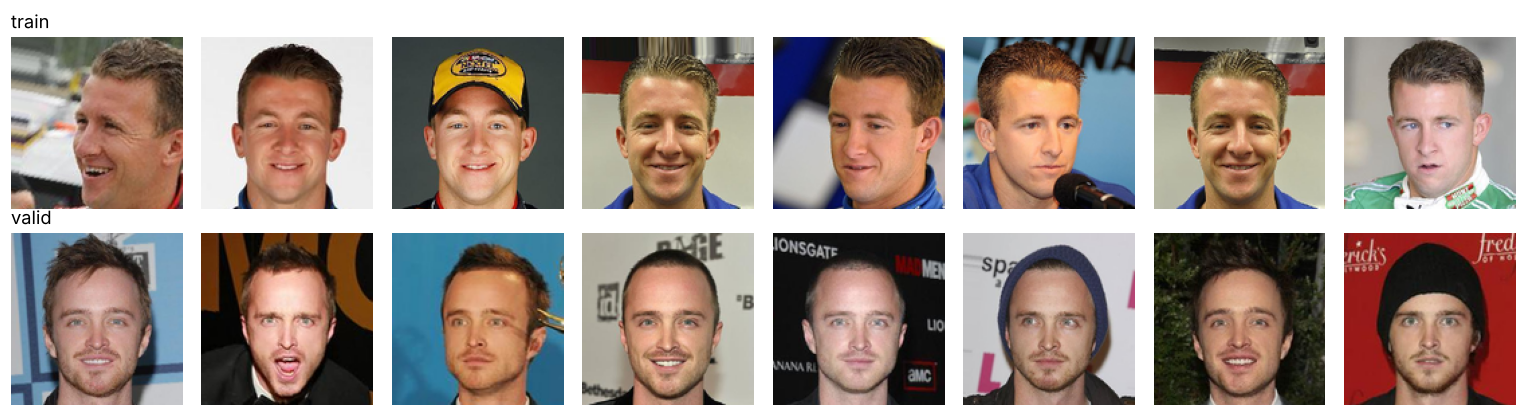

In [2]:
DATA_DIR = "data"
HF = "https://huggingface.co/datasets/flwrlabs/celeba/resolve/main/img_align+identity+attr/"
SHARDS = {"train": "train-00000-of-00019.parquet", "valid": "valid-00000-of-00003.parquet"}
os.makedirs(DATA_DIR, exist_ok=True)

def to_128(png_bytes):
    im = Image.open(io.BytesIO(png_bytes)).convert("RGB")           # 178×218
    w, h = im.size
    top = (h - w) // 2                                               # 20
    im = im.crop((0, top, w, top + w))                               # 178×178
    return np.asarray(im.resize((128, 128), Image.Resampling.LANCZOS))

def load_split(split, n):
    cache = os.path.join(DATA_DIR, f"celeba128_{split}_{n}.npy")
    if os.path.exists(cache):
        return np.load(cache)
    path = os.path.join(DATA_DIR, SHARDS[split])
    if not os.path.exists(path):
        print("скачиваю", SHARDS[split]); urllib.request.urlretrieve(HF + SHARDS[split], path)
    imgs = []
    for batch in pq.ParquetFile(path).iter_batches(batch_size=256, columns=["image"]):
        for rec in batch.column("image").to_pylist():
            imgs.append(to_128(rec["bytes"]))
            if len(imgs) == n:
                break
        if len(imgs) == n:
            break
    arr = np.stack(imgs)
    np.save(cache, arr)
    return arr

t0 = time.time()
X_train_np = load_split("train", CFG["N_TRAIN"])
X_val_np = load_split("valid", CFG["N_VAL"])
print(f"train: {X_train_np.shape}, val: {X_val_np.shape}, dtype={X_train_np.dtype}, {time.time() - t0:.0f} c")

X_train = torch.from_numpy(X_train_np).permute(0, 3, 1, 2).contiguous()   # uint8 NCHW
X_val = torch.from_numpy(X_val_np).permute(0, 3, 1, 2).float().div(255)

fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_np[i] if i < 8 else X_val_np[i - 8]); ax.axis("off")
axes[0, 0].set_title("train", loc="left"); axes[1, 0].set_title("valid", loc="left")
plt.tight_layout(); plt.show()

## 2. Архитектура

```
             g_a (энкодер)                                     g_s (декодер)
x 128×128×3 → Conv5×5/2 → GDN → Conv5×5/2 → GDN →      ŷ 8×8×128 → Up → IGDN → Up → IGDN →
            → Conv5×5/2 → GDN → Conv5×5/2 → y 8×8×128            → Up → IGDN → Up → x̂ 128×128×3
                         │                                            ▲
                    h_a: Conv3×3 → LReLU → Conv5×5/2 → LReLU → Conv5×5/2 → z 2×2×64
                                                                       │ round → ẑ, ANS(factorized prior)
                    h_s: Up → LReLU → Up → LReLU → Conv3×3 → (μ, σ) для каждого элемента ŷ
```

* **GDN** (Generalized Divisive Normalization, Ballé et al., 2016):
  $y_i = x_i / \sqrt{\beta_i + \sum_j \gamma_{ij} x_j^2}$. Это нормализующая нелинейность, хорошо «гауссианизирующая»
  статистику изображений. В декодере используется обратная к ней IGDN. Положительность β и γ обеспечивается
  репараметризацией с нижней границей.
* **Up** — исследуемый блок увеличения размера ×2 (раздел 3). В гипердекодере $h_s$ во всех вариантах используется
  транспонированная свёртка, чтобы сравнение касалось только основного декодера.
* **Энтропийные модели:** факторизованная непараметрическая плотность для $z$ (кумулятивная функция задаётся
  монотонной мини-сетью по каждому каналу) и условный гауссиан для $y$.

In [3]:
# ============================================================ базовые блоки
class _LowerBound(torch.autograd.Function):
    # clamp_min, но градиент пропускается, если он тянет значение вверх (не «залипаем» на границе)
    @staticmethod
    def forward(ctx, x, bound):
        ctx.save_for_backward(x); ctx.bound = bound
        return torch.clamp_min(x, bound)

    @staticmethod
    def backward(ctx, g):
        (x,) = ctx.saved_tensors
        return g * ((x >= ctx.bound) | (g < 0)).to(g.dtype), None

def lower_bound(x, b):
    return _LowerBound.apply(x, b)


class GDN(nn.Module):
    # GDN / IGDN (Ballé et al., 2016)
    def __init__(self, ch, inverse=False, beta_min=1e-6, gamma_init=0.1, offset=2 ** -18):
        super().__init__()
        self.inverse, self.pedestal = inverse, offset ** 2
        self.beta_bound = (beta_min + self.pedestal) ** 0.5
        self.gamma_bound = offset
        self.beta = nn.Parameter(torch.sqrt(torch.ones(ch) + self.pedestal))
        self.gamma = nn.Parameter(torch.sqrt(gamma_init * torch.eye(ch) + self.pedestal))

    def forward(self, x):
        with torch.autocast(x.device.type, enabled=False):          # нормализация — в float32
            x = x.float()
            beta = lower_bound(self.beta, self.beta_bound) ** 2 - self.pedestal
            gamma = lower_bound(self.gamma, self.gamma_bound) ** 2 - self.pedestal
            norm = torch.sqrt(F.conv2d(x * x, gamma[:, :, None, None], beta))
            return x * norm if self.inverse else x / norm


def conv(cin, cout, k=5, s=2):
    return nn.Conv2d(cin, cout, k, s, k // 2)

## 3. Четыре способа увеличить размер тензора в декодере

| Вариант | Реализация (×2) | Комментарий |
|---|---|---|
| 1. **Транспонированная свёртка** | `ConvTranspose2d(k=5, s=2, p=2, output_padding=1)` | классика Ballé et al.; может давать «шахматные» артефакты |
| 2. **Билинейная интерполяция + свёртка** | `Upsample(bilinear) → Conv2d(k=5)` | нет «шахматки», но свёртка работает на выходном разрешении: в 4 раза больше вычислений |
| 3. **Sub-Pixel Convolution** | `Conv2d(cin → 4·cout, k=3) → PixelShuffle(2)` | Shi et al., 2016; ICNR-инициализация против «шахматки». Ядро 3×3, потому что при 5×5 у слоя было бы в 4 раза больше весов, чем у остальных вариантов (4·25 против 25 на пару каналов), а при 3×3 их 4·9 = 36 — ёмкость сопоставима |
| 4. **Max Unpooling + свёртка** | `MaxUnpool2d(2) → Conv2d(k=5)` | см. разбор ниже |

**Тонкость с Max Unpooling в задаче сжатия.** `MaxUnpool2d` нужны индексы (switches): позиции максимумов, запомненные
`MaxPool2d` в энкодере. Декодер кодека видит **только битовый поток**, поэтому возможны два варианта:

* **4a. Фиксированные индексы** (значение ставится в левый верхний угол каждого блока 2×2, остальное — нули).
  Это валидный кодек, но такая операция — вставка нулей с последующей свёрткой. Ровно так устроена
  транспонированная свёртка, поэтому вариант 4a **математически эквивалентен варианту 1**. Ниже это проверено численно.
* **4b. Настоящие индексы из энкодера** (энкодер на `Conv(stride 1) + MaxPool`). Декодер получает
  информацию «бесплатно», то есть это **оракул**. Чтобы такой кодек был честным, индексы нужно передавать.
  Их стоимость оценивается отдельно по эмпирической энтропии.

In [4]:
class SubPixelUp(nn.Module):
    def __init__(self, cin, cout, k=5):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout * 4, k, 1, k // 2)
        self.ps = nn.PixelShuffle(2)
        w = torch.empty(cout, cin, k, k); nn.init.kaiming_uniform_(w, a=math.sqrt(5))
        self.conv.weight.data.copy_(w.repeat_interleave(4, dim=0))      # ICNR (Aitken et al., 2017)

    def forward(self, x):
        return self.ps(self.conv(x))


class FixedUnpoolUp(nn.Module):
    # MaxUnpool2d с фиксированными индексами (левый верхний угол блока 2×2) + Conv
    def __init__(self, cin, cout, k=5):
        super().__init__()
        self.unpool = nn.MaxUnpool2d(2)
        self.conv = nn.Conv2d(cin, cout, k, 1, k // 2)

    def forward(self, x):
        B, C, H, W = x.shape
        idx = (torch.arange(H, device=x.device)[:, None] * 2 * (2 * W) + torch.arange(W, device=x.device)[None, :] * 2)
        return self.conv(self.unpool(x.float(), idx.expand(B, C, H, W)).to(x.dtype))


def make_up(cin, cout, method, k=5):
    if method == "transposed":
        return nn.ConvTranspose2d(cin, cout, k, 2, k // 2, output_padding=1)
    if method == "bilinear":
        return nn.Sequential(nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False), nn.Conv2d(cin, cout, k, 1, k // 2))
    if method == "subpixel":
        return SubPixelUp(cin, cout, 3)    # k=3: 4·9=36 весов на пару каналов против 25 у остальных — сопоставимая ёмкость
    if method == "unpool_fixed":
        return FixedUnpoolUp(cin, cout, k)
    raise ValueError(method)


# --- численная проверка: MaxUnpool(фикс. индексы)+Conv ≡ ConvTranspose2d с перевёрнутым ядром ---
torch.manual_seed(0)
tconv = make_up(16, 8, "transposed")
unp = make_up(16, 8, "unpool_fixed")
with torch.no_grad():
    unp.conv.weight.copy_(tconv.weight.transpose(0, 1).flip(2, 3))   # W_conv[o,i,a,b] = W_t[i,o,4-a,4-b]
    unp.conv.bias.copy_(tconv.bias)
x_test = torch.randn(4, 16, 8, 8)
diff = (tconv(x_test) - unp(x_test)).abs().max().item()
print(f"max |ConvTranspose2d(x) − Conv(MaxUnpool_fixed(x))| = {diff:.2e}  -> эквивалентны: {diff < 1e-5}")

max |ConvTranspose2d(x) − Conv(MaxUnpool_fixed(x))| = 7.15e-07  -> эквивалентны: True


Расхождение на уровне ошибки округления float32: вариант 4a и транспонированная свёртка задают **одно и то же семейство
функций**, а их параметры связаны перестановкой (поворот ядра на 180° и транспонирование). Adam покоординатно инвариантен
к перестановкам, поэтому при одинаковой инициализации обучение 4a и варианта 1 даёт идентичные траектории.
Отдельно 4a не обучается: его результаты совпадают с вариантом 1. Обучается содержательный вариант **4b**.

## 4. Энтропийные модели и сама модель

In [5]:
class FactorizedPrior(nn.Module):
    # Непараметрическая факторизованная плотность (Ballé et al., 2018, прил. 6.1): CDF_c(v) = sigmoid(MLP_c(v)),
    # MLP монотонна по v (положительные веса через softplus).
    def __init__(self, channels, filters=(3, 3, 3), init_scale=10.0):
        super().__init__()
        f = (1,) + tuple(filters) + (1,)
        scale = init_scale ** (1 / (len(f) - 1))
        self.matrices, self.biases, self.factors = nn.ParameterList(), nn.ParameterList(), nn.ParameterList()
        for i in range(len(f) - 1):
            init = math.log(math.expm1(1 / scale / f[i + 1]))
            self.matrices.append(nn.Parameter(torch.full((channels, f[i + 1], f[i]), init)))
            self.biases.append(nn.Parameter(torch.rand(channels, f[i + 1], 1) - 0.5))
            if i < len(f) - 2:
                self.factors.append(nn.Parameter(torch.zeros(channels, f[i + 1], 1)))

    def _logits_cdf(self, v):                       # v: (C, 1, n)
        for i, (m, b) in enumerate(zip(self.matrices, self.biases)):
            v = torch.matmul(F.softplus(m), v) + b
            if i < len(self.factors):
                v = v + torch.tanh(self.factors[i]) * torch.tanh(v)
        return v

    def _prob(self, v):                             # P(v-0.5 < Z < v+0.5)
        lo, up = self._logits_cdf(v - 0.5), self._logits_cdf(v + 0.5)
        sign = -torch.sign(lo + up).detach()        # считаем в «хвосте», где точность float выше
        return torch.abs(torch.sigmoid(sign * up) - torch.sigmoid(sign * lo))

    def likelihood(self, z):                        # z: (B, C, H, W)
        B, C, H, W = z.shape
        p = self._prob(z.permute(1, 0, 2, 3).reshape(C, 1, -1))
        return p.reshape(C, B, H, W).permute(1, 0, 2, 3)

    @torch.no_grad()
    def pmf_table(self, R):                         # (C, 2R+1) — вероятности символов -R..R для ANS
        C = self.matrices[0].shape[0]
        k = torch.arange(-R, R + 1, dtype=torch.float32)[None, None, :].expand(C, 1, -1)
        return self._prob(k)[:, 0, :]


SCALE_MIN = 0.11
LIK_MIN = 1e-9      # нижняя граница правдоподобия: иначе log2(0) = −inf и NaN в градиентах

def gaussian_likelihood(y, mu, sigma):
    sigma = lower_bound(sigma, SCALE_MIN)
    v = torch.abs(y - mu)                           # симметрия: считаем в левом хвосте
    c = 1 / math.sqrt(2)
    return 0.5 * torch.erfc(-c * (0.5 - v) / sigma) - 0.5 * torch.erfc(-c * (-0.5 - v) / sigma)

def ste_round(x):
    return x + (torch.round(x) - x).detach()


class HyperpriorVAE(nn.Module):
    def __init__(self, N=64, M=128, up="transposed"):
        super().__init__()
        self.N, self.M, self.up = N, M, up
        self.g_a = nn.Sequential(conv(3, N), GDN(N), conv(N, N), GDN(N), conv(N, N), GDN(N), conv(N, M))
        self.g_s = nn.Sequential(make_up(M, N, up), GDN(N, True), make_up(N, N, up), GDN(N, True),
                                 make_up(N, N, up), GDN(N, True), make_up(N, 3, up))
        self.h_a = nn.Sequential(conv(M, N, 3, 1), nn.LeakyReLU(inplace=True), conv(N, N, 5, 2),
                                 nn.LeakyReLU(inplace=True), conv(N, N, 5, 2))
        self.h_s = nn.Sequential(make_up(N, N, "transposed"), nn.LeakyReLU(inplace=True),
                                 make_up(N, M, "transposed"), nn.LeakyReLU(inplace=True), conv(M, 2 * M, 3, 1))
        self.prior_z = FactorizedPrior(N)

    # энкодер/декодер вынесены отдельно, чтобы вариант с MaxPool мог передавать индексы
    def encode(self, x):
        return self.g_a(x), None

    def decode(self, y_hat, aux=None):
        return self.g_s(y_hat)

    def hyper(self, z_hat):
        with torch.autocast(z_hat.device.type, enabled=False):
            mu, s = self.h_s(z_hat.float().contiguous()).chunk(2, 1)
        return mu, F.softplus(s)

    def forward(self, x):
        y, aux = self.encode(x)
        z = self.h_a(y)
        with torch.autocast(x.device.type, enabled=False):
            y, z = y.float(), z.float()
            noisy = self.training
            z_rate = z + torch.empty_like(z).uniform_(-0.5, 0.5) if noisy else torch.round(z)
            lik_z = lower_bound(self.prior_z.likelihood(z_rate), LIK_MIN)
            mu, sigma = self.hyper(ste_round(z))
            y_rate = y + torch.empty_like(y).uniform_(-0.5, 0.5) if noisy else torch.round(y)
            lik_y = lower_bound(gaussian_likelihood(y_rate, mu, sigma), LIK_MIN)
            y_hat = ste_round(y)
        x_hat = self.decode(y_hat, aux)
        return dict(x_hat=x_hat.float(), lik_y=lik_y, lik_z=lik_z, y=y, z=z, mu=mu, sigma=sigma, aux=aux)


class MaxPoolOracleVAE(HyperpriorVAE):
    # Вариант 4b: энкодер Conv(s=1)+MaxPool, декодер MaxUnpool(индексы энкодера)+Conv. Индексы НЕ входят в битовый поток.
    def __init__(self, N=64, M=128):
        super().__init__(N, M, up="transposed")
        del self.g_a, self.g_s
        self.enc = nn.ModuleList([nn.Conv2d(3, N, 5, 1, 2), nn.Conv2d(N, N, 5, 1, 2), nn.Conv2d(N, N, 5, 1, 2), nn.Conv2d(N, M, 5, 1, 2)])
        self.enc_gdn = nn.ModuleList([GDN(N) for _ in range(3)])
        self.dec = nn.ModuleList([nn.Conv2d(M, N, 5, 1, 2), nn.Conv2d(N, N, 5, 1, 2), nn.Conv2d(N, N, 5, 1, 2), nn.Conv2d(N, 3, 5, 1, 2)])
        self.dec_gdn = nn.ModuleList([GDN(N, inverse=True) for _ in range(3)])
        self.pool, self.unpool = nn.MaxPool2d(2, return_indices=True), nn.MaxUnpool2d(2)
        self.up = "maxunpool_oracle"

    def encode(self, x):
        idx = []
        for i, c in enumerate(self.enc):
            x, ind = self.pool(c(x).float())
            idx.append(ind)
            if i < 3:
                x = self.enc_gdn[i](x)
        return x, idx

    def decode(self, y_hat, idx):
        x = y_hat
        for i, c in enumerate(self.dec):
            x = c(self.unpool(x.float(), idx[3 - i]))
            if i < 3:
                x = self.dec_gdn[i](x)
        return x


def n_params(m):
    return sum(p.numel() for p in m.parameters())

@torch.no_grad()
def count_gmacs(model, x):
    # Умножения-сложения (MAC) свёрток энкодера g_a и декодера g_s на одно изображение (без GDN и гиперприора).
    # Аналитический подсчёт через forward-хуки: не зависит от загрузки CPU, в отличие от времени обучения.
    macs = {"n": 0}
    def hook(m, inp, out):
        if isinstance(m, nn.ConvTranspose2d):
            macs["n"] += inp[0][0].numel() * m.out_channels * m.kernel_size[0] * m.kernel_size[1]
        else:
            macs["n"] += out[0].numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
    convs = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d))]
    hs = [m.register_forward_hook(hook) for m in convs]
    model.eval()
    y, aux = model.encode(x[:1]); enc = macs["n"]
    macs["n"] = 0; model.decode(torch.round(y), aux); dec = macs["n"]
    for h in hs: h.remove()
    return enc / 1e9, dec / 1e9

_x = torch.rand(1, 3, 128, 128)
for up in ["transposed", "bilinear", "subpixel", "maxunpool_oracle"]:
    m = MaxPoolOracleVAE(CFG["N"], CFG["M"]) if up == "maxunpool_oracle" else HyperpriorVAE(CFG["N"], CFG["M"], up)
    e, d = count_gmacs(m, _x)
    print(f"{up:<17} параметров: {n_params(m) / 1e6:.3f} M | GMAC/изобр. 128×128: энкодер {e:.3f}, декодер {d:.3f}")
with torch.no_grad():
    o = HyperpriorVAE(CFG["N"], CFG["M"]).eval()(X_val[:2])
print("формы: x_hat", tuple(o["x_hat"].shape), "| y", tuple(o["y"].shape), "| z", tuple(o["z"].shape))

transposed        параметров: 1.738 M | GMAC/изобр. 128×128: энкодер 0.164, декодер 0.164
bilinear          параметров: 1.738 M | GMAC/изобр. 128×128: энкодер 0.164, декодер 0.655
subpixel          параметров: 1.921 M | GMAC/изобр. 128×128: энкодер 0.164, декодер 0.236
maxunpool_oracle  параметров: 1.738 M | GMAC/изобр. 128×128: энкодер 0.655, декодер 0.655


формы: x_hat (2, 3, 128, 128) | y (2, 128, 8, 8) | z (2, 64, 2, 2)


## 5. Функция потерь, градиентное обрезание, обучение

Используется вторая функция ошибки из задания:

$$\text{Loss} = \lambda\cdot\text{BPP} + \alpha\cdot\text{MSE} + \beta\cdot(1-\text{MS-SSIM}) + \gamma\cdot\text{LPIPS},\qquad
\alpha = 20,\ \beta = 1,\ \gamma = 0.25.$$

Она выбрана вместо $\lambda\cdot\text{BPP} + (1-\text{MS-SSIM})$, потому что качество оценивается сразу по трём метрикам.
Слагаемое MSE отвечает за PSNR и цвет: MS-SSIM почти не штрафует сдвиг яркости и цвета. LPIPS отвечает за перцептивное
качество, а MS-SSIM — за структуру. Веса подобраны так, чтобы при типичном качестве (PSNR ≈ 28–30 дБ,
1−MS-SSIM ≈ 0.03–0.05, LPIPS ≈ 0.1–0.2) вклады трёх слагаемых были сопоставимы.

* **MS-SSIM** реализован вручную, а для проверки сверен с `pytorch_msssim`. Для 128×128: стандартные 5 масштабов
  с весами Wang et al. (2003), но окно 7×7 вместо 11×11: окно 11×11 на самом грубом масштабе 8×8 не помещается.
  На обучающих кропах 64×64 используются 4 масштаба с перенормированными весами. Оценка на валидации всегда идёт
  по полным 128×128 и 5 масштабам.
* **LPIPS** (Zhang et al., 2018) — версия `alex` (v0.1), веса сети заморожены.
* **Градиентное обрезание:** выбрано обрезание по **глобальной L2-норме** (`clip_grad_norm_`, порог 1.0),
  стандартное для обучения learned-кодеков. В начале обучения GDN и энтропийные модели дают редкие очень большие градиенты,
  а обрезание по глобальной норме гасит такие выбросы, не меняя направления шага. Норма градиента до обрезания и факт
  срабатывания логируются на каждом шаге.
* **Обучение на кропах.** Изображения приведены к 128×128 (раздел 1). Для обучения из них вырезаются случайные кропы
  64×64 — стандартная практика для learned-кодеков: CompressAI обучает на кропах 256×256. Модель полностью свёрточная,
  поэтому валидация и сжатие выполняются на **полных 128×128**. Кроп в 4 раза дешевле, и на CPU за то же время
  получается в 4 раза больше шагов оптимизации. Пробный запуск показал, что за равное время это даёт заметно лучшее
  качество на валидации, чем обучение на полных изображениях.
* Adam, `lr = 10⁻³`: линейный разогрев за 200 шагов, затем косинусное затухание до 10% к концу этапа. Батч 16,
  аугментация — горизонтальное отражение.
* `lr = 10⁻³` без нижней границы правдоподобий давал NaN в первые же шаги: при $p\to 0$ получается $\log_2 p = -\infty$.
  Поэтому правдоподобия ограничены снизу значением $10^{-9}$, с пропуском градиента вверх, как и в GDN.

In [6]:
lpips_net = lpips.LPIPS(net="alex", verbose=False).eval().to(DEVICE)
for p in lpips_net.parameters():
    p.requires_grad_(False)

MS_W = [0.0448, 0.2856, 0.3001, 0.2363, 0.1333]          # веса масштабов MS-SSIM (Wang et al., 2003)

def _gauss_win(size, sigma):
    t = torch.arange(size, dtype=torch.float32) - size // 2
    g = torch.exp(-t ** 2 / (2 * sigma ** 2))
    return g / g.sum()

def _ssim_cs(x, y, win, C1, C2):
    # SSIM и contrast-structure по каждому каналу; сепарабельный гауссов фильтр без паддинга
    C = x.shape[1]
    wh, wv = win.view(1, 1, 1, -1).repeat(C, 1, 1, 1), win.view(1, 1, -1, 1).repeat(C, 1, 1, 1)
    f = lambda t: F.conv2d(F.conv2d(t, wh, groups=C), wv, groups=C)
    mx, my = f(x), f(y)
    sxx, syy, sxy = f(x * x) - mx ** 2, f(y * y) - my ** 2, f(x * y) - mx * my
    cs = (2 * sxy + C2) / (sxx + syy + C2)
    ssim = (2 * mx * my + C1) / (mx ** 2 + my ** 2 + C1) * cs
    return ssim.flatten(2).mean(-1), cs.flatten(2).mean(-1)

def msssim_fn(x, y, weights=None, win_size=7, sigma=1.5, data_range=1.0):
    # Собственная реализация MS-SSIM (Wang et al., 2003): произведение cs по масштабам 1..L-1 и SSIM на масштабе L,
    # в степенях weights. Для 128×128 — 5 масштабов; для обучающих кропов 64×64 — 4 (веса перенормированы).
    if weights is None:
        weights = MS_W if min(x.shape[-2:]) > (win_size - 1) * 2 ** 4 else [v / sum(MS_W[:4]) for v in MS_W[:4]]
    C1, C2 = (0.01 * data_range) ** 2, (0.03 * data_range) ** 2
    win = _gauss_win(win_size, sigma).to(x)
    vals = []
    for i in range(len(weights)):
        ssim_c, cs = _ssim_cs(x, y, win, C1, C2)
        if i < len(weights) - 1:
            vals.append(torch.relu(cs))
            pad = [s % 2 for s in x.shape[2:]]
            x, y = F.avg_pool2d(x, 2, padding=pad), F.avg_pool2d(y, 2, padding=pad)
    vals.append(torch.relu(ssim_c))
    w = torch.tensor(weights, dtype=x.dtype, device=x.device).view(-1, 1, 1)
    return torch.prod(torch.stack(vals) ** w, dim=0).mean(1)          # (B,)

# проверка своей реализации против pytorch_msssim (128×128, 5 масштабов, окно 7)
_a = torch.rand(4, 3, 128, 128); _b = (_a + 0.1 * torch.randn_like(_a)).clamp(0, 1)
print("MS-SSIM: своя =", msssim_fn(_a, _b).numpy().round(6), "| pytorch_msssim =",
      ms_ssim(_a, _b, data_range=1.0, size_average=False, win_size=7).numpy().round(6))

def lpips_fn(a, b):
    return lpips_net(a * 2 - 1, b * 2 - 1).flatten()

def bpp_of(out, n_pixels):
    return (-torch.log2(out["lik_y"]).sum() - torch.log2(out["lik_z"]).sum()) / n_pixels

def rd_loss(out, x, lam):
    x_hat = out["x_hat"]
    n_pix = x.shape[0] * x.shape[2] * x.shape[3]
    bpp = bpp_of(out, n_pix)
    mse = F.mse_loss(x_hat, x)
    msssim = msssim_fn(x_hat, x).mean()
    with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=AMP):
        lp = lpips_fn(x_hat, x).float().mean()
    loss = lam * bpp + CFG["ALPHA"] * mse + CFG["BETA"] * (1 - msssim) + CFG["GAMMA"] * lp
    return loss, dict(loss=loss.item(), bpp=bpp.item(), mse=mse.item(), psnr=-10 * math.log10(max(mse.item(), 1e-10)),
                      msssim=msssim.item(), lpips=lp.item())


@torch.no_grad()
def quick_val(model, lam, n=64):
    model.eval()
    x = X_val[:n].to(DEVICE)
    with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=AMP):
        out = model(x)
    _, m = rd_loss(out, x, lam)
    model.train()
    return m


WARMUP = 200

def train(model, lam, steps, name, lr=None, log_every=100, val_every=500, seed=0):
    # Обучение на случайных батчах из X_train. Возвращает DataFrame с журналом (train-метрики, ‖g‖, val).
    lr = lr or CFG["LR"]
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    warm = min(WARMUP, steps // 5)      # линейный разогрев lr, затем косинус до 10%
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                              0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min((s - warm) / max(steps - warm, 1), 1))))
    model.train().to(DEVICE)
    log, buf, t0 = [], [], time.time()
    for step in range(1, steps + 1):
        idx = torch.randint(0, len(X_train), (CFG["BATCH"],), generator=g)
        x = X_train[idx]
        if CFG["CROP"] < x.shape[-1]:                                  # случайный кроп из изображения 128×128
            i0, j0 = torch.randint(0, x.shape[-1] - CFG["CROP"] + 1, (2,), generator=g).tolist()
            x = x[..., i0:i0 + CFG["CROP"], j0:j0 + CFG["CROP"]]
        x = x.float().div_(255)
        flip = torch.rand(len(x), generator=g) < 0.5
        x[flip] = x[flip].flip(-1)
        x = x.to(DEVICE)
        with torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=AMP):
            out = model(x)
        loss, m = rd_loss(out, x, lam)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP_NORM"]).item()   # градиентное обрезание
        opt.step(); sched.step()
        m.update(gnorm=gnorm, clipped=float(gnorm > CFG["CLIP_NORM"]))
        buf.append(m)
        if step % log_every == 0 or step == steps:
            row = {k: float(np.mean([b[k] for b in buf])) for k in buf[0]}
            row.update(step=step, lr=sched.get_last_lr()[0], time=time.time() - t0)
            buf = []
            if step % val_every == 0 or step == steps:
                row.update({f"val_{k}": v for k, v in quick_val(model, lam).items()})
                msg = (f"[{name}] step {step:5d}/{steps} | loss {row['loss']:.4f} | bpp {row['bpp']:.3f} | PSNR {row['psnr']:.2f} | "
                       f"MS-SSIM {row['msssim']:.4f} | LPIPS {row['lpips']:.4f} | ‖g‖ {row['gnorm']:.2f} (обрезано {row['clipped']:.0%}) | "
                       f"val: bpp {row['val_bpp']:.3f} PSNR {row['val_psnr']:.2f} LPIPS {row['val_lpips']:.4f} | {row['time'] / 60:.1f} мин")
                print(msg)
                with open("artifacts/train_log.txt", "a") as fh:
                    fh.write(msg + "\n")
            log.append(row)
    model.eval()
    return pd.DataFrame(log)

MS-SSIM: своя = [0.955897 0.951866 0.954242 0.955283] | pytorch_msssim = [0.955898 0.951865 0.954242 0.955282]


## 6. Эксперимент 1: сравнение способов увеличения размера тензора

Все варианты обучаются при одном и том же λ = λ_mid, с одинаковыми seed, числом шагов и функцией потерь.
Энкодер, гиперприор и энтропийные модели у вариантов 1–3 одинаковы, различается только блок Up в $g_s$.

In [7]:
os.makedirs("checkpoints", exist_ok=True); os.makedirs("artifacts", exist_ok=True)
VARIANTS = {"transposed": "1. ConvTranspose", "bilinear": "2. Bilinear + Conv", "subpixel": "3. Sub-Pixel (PixelShuffle)",
            "maxunpool_oracle": "4b. MaxPool/MaxUnpool (оракул)"}
MODELS, LOGS = {}, {}
lam = CFG["LAMBDA_MID"]
for key in VARIANTS:
    torch.manual_seed(SEED)
    model = MaxPoolOracleVAE(CFG["N"], CFG["M"]) if key == "maxunpool_oracle" else HyperpriorVAE(CFG["N"], CFG["M"], key)
    LOGS[key] = train(model, lam, CFG["STEPS_COMPARE"], key)
    MODELS[key] = model
    torch.save(model.state_dict(), f"checkpoints/{key}_lam{lam}.pt")
    LOGS[key].to_csv(f"artifacts/log_{key}.csv", index=False)
    print()

[transposed] step   500/3000 | loss 0.4477 | bpp 0.585 | PSNR 20.21 | MS-SSIM 0.8546 | LPIPS 0.1981 | ‖g‖ 4.08 (обрезано 100%) | val: bpp 0.593 PSNR 20.87 LPIPS 0.2399 | 1.5 мин


[transposed] step  1000/3000 | loss 0.2906 | bpp 0.579 | PSNR 22.55 | MS-SSIM 0.9131 | LPIPS 0.1343 | ‖g‖ 2.60 (обрезано 91%) | val: bpp 0.532 PSNR 22.66 LPIPS 0.1569 | 3.0 мин


[transposed] step  1500/3000 | loss 0.2086 | bpp 0.546 | PSNR 24.38 | MS-SSIM 0.9411 | LPIPS 0.0854 | ‖g‖ 1.59 (обрезано 65%) | val: bpp 0.506 PSNR 25.06 LPIPS 0.1126 | 4.6 мин


[transposed] step  2000/3000 | loss 0.1724 | bpp 0.537 | PSNR 25.45 | MS-SSIM 0.9555 | LPIPS 0.0661 | ‖g‖ 0.57 (обрезано 7%) | val: bpp 0.513 PSNR 25.90 LPIPS 0.0869 | 6.1 мин


[transposed] step  2500/3000 | loss 0.1592 | bpp 0.531 | PSNR 25.87 | MS-SSIM 0.9613 | LPIPS 0.0600 | ‖g‖ 0.41 (обрезано 1%) | val: bpp 0.524 PSNR 26.56 LPIPS 0.0777 | 7.6 мин


[transposed] step  3000/3000 | loss 0.1508 | bpp 0.530 | PSNR 26.18 | MS-SSIM 0.9647 | LPIPS 0.0548 | ‖g‖ 0.31 (обрезано 0%) | val: bpp 0.541 PSNR 26.86 LPIPS 0.0733 | 9.2 мин



... (14 outputs left out)

[maxunpool_oracle] step  1500/3000 | loss 0.1608 | bpp 0.189 | PSNR 24.75 | MS-SSIM 0.9442 | LPIPS 0.0663 | ‖g‖ 2.87 (обрезано 92%) | val: bpp 0.382 PSNR 24.68 LPIPS 0.1108 | 7.1 мин


[maxunpool_oracle] step  2000/3000 | loss 0.1249 | bpp 0.170 | PSNR 26.18 | MS-SSIM 0.9535 | LPIPS 0.0479 | ‖g‖ 1.91 (обрезано 74%) | val: bpp 0.453 PSNR 24.21 LPIPS 0.0818 | 9.3 мин


[maxunpool_oracle] step  2500/3000 | loss 0.1028 | bpp 0.154 | PSNR 27.26 | MS-SSIM 0.9605 | LPIPS 0.0389 | ‖g‖ 1.25 (обрезано 59%) | val: bpp 0.534 PSNR 26.02 LPIPS 0.0737 | 11.6 мин


[maxunpool_oracle] step  3000/3000 | loss 0.0956 | bpp 0.150 | PSNR 27.67 | MS-SSIM 0.9629 | LPIPS 0.0358 | ‖g‖ 0.91 (обрезано 36%) | val: bpp 0.596 PSNR 25.89 LPIPS 0.0739 | 13.9 мин



### Метрики на валидации (500 изображений) и реальный битрейт

Функции ниже — полный кодек:

* `compress`: $y = g_a(x)$, $z = h_a(y)$, затем $\hat z = \mathrm{round}(z)$ кодируется ANS по таблице вероятностей
  факторизованной модели, а $\hat y = \mathrm{round}(y)$ кодируется ANS с квантованным гауссианом $(\mu, \sigma) = h_s(\hat z)$.
* `decompress`: из битового потока сначала декодируется $\hat z$, по нему восстанавливаются $(\mu,\sigma)$, затем $\hat y$
  и $\hat x = g_s(\hat y)$.

Реальный BPP — это длина битового потока (слова по 32 бита) плюс заголовок с размерами, делённые на 128·128.

**Детерминизм энкодера и декодера.** Энтропийный кодер требует, чтобы при кодировании и декодировании вероятности
символов совпадали **бит в бит**. На этом спотыкаются многие learned-кодеки. При отладке обнаружилось, что $z$
после свёртки хранится в памяти в формате `channels_last`, а $\hat z$, восстановленный декодером из символов, — в обычном
формате. Свёртка $h_s$ на этих двух тензорах суммирует в разном порядке, и $\mu$ отличается на ~$10^{-8}$.
Этого хватает, чтобы ANS рассинхронизировался. Поэтому энкодер считает $(\mu,\sigma)$ **из тех же символов
и тем же путём**, что и декодер. Первые 8 изображений каждой модели проходят полный цикл
«сжатие → распаковка» с проверкой точного совпадения символов.

In [8]:
R_Y, R_Z = 255, 63          # диапазон символов для ANS (значения вне диапазона обрезаются; проверяем, что их нет)
Y_FAMILY = constriction.stream.model.QuantizedGaussian(-R_Y, R_Y)
Z_FAMILY = constriction.stream.model.Categorical(perfect=False)
HEADER_BYTES = 2            # высота и ширина латента (по 1 байту) — минимальный «заголовок» файла

@torch.no_grad()
def compress(model, x):
    # x: (1,3,H,W) -> (uint32 bitstream, aux). Для оракула aux = индексы MaxPool (в поток не входят!)
    model.eval()
    y, aux = model.encode(x)
    z = model.h_a(y)
    z_sym = (torch.round(z.float()).clamp(-R_Z, R_Z) + R_Z).int().contiguous().numpy()   # (1,C,h,w), C-порядок
    # μ, σ считаем из ẑ, восстановленного из символов — ровно как в декодере (см. примечание ниже)
    z_hat = torch.from_numpy(z_sym.astype(np.float32) - R_Z)
    mu, sigma = model.hyper(z_hat)
    y_sym = torch.round(y.float()).clamp(-R_Y, R_Y).int().numpy().ravel()
    pmf = model.prior_z.pmf_table(R_Z).double().numpy()                     # (C, 2R+1)
    pmf = pmf / pmf.sum(1, keepdims=True)
    z_probs = np.repeat(pmf, z_sym.shape[2] * z_sym.shape[3], axis=0)       # строка для каждого символа z (порядок C,h,w)
    coder = constriction.stream.stack.AnsCoder()
    coder.encode_reverse(y_sym.astype(np.int32), Y_FAMILY, mu.double().numpy().ravel(),
                         lower_bound(sigma, SCALE_MIN).double().numpy().ravel())
    coder.encode_reverse(z_sym.ravel().astype(np.int32), Z_FAMILY, z_probs)  # z последним -> декодируется первым
    clipped = int((torch.round(y.float()).abs() > R_Y).sum() + (torch.round(z.float()).abs() > R_Z).sum())
    return coder.get_compressed(), dict(aux=aux, y_shape=tuple(y.shape), z_shape=tuple(z.shape), n_clipped=clipped,
                                        y_sym=y_sym, z_sym=z_sym.ravel())

@torch.no_grad()
def decompress(model, bits, meta):
    dec = constriction.stream.stack.AnsCoder(bits)
    _, C, h, w = meta["z_shape"]
    pmf = model.prior_z.pmf_table(R_Z).double().numpy(); pmf = pmf / pmf.sum(1, keepdims=True)
    z_sym = dec.decode(Z_FAMILY, np.repeat(pmf, h * w, axis=0))
    z_hat = torch.from_numpy(z_sym.astype(np.float32) - R_Z).reshape(1, C, h, w)
    mu, sigma = model.hyper(z_hat)
    y_sym = dec.decode(Y_FAMILY, mu.double().numpy().ravel(), lower_bound(sigma, SCALE_MIN).double().numpy().ravel())
    y_hat = torch.from_numpy(y_sym.astype(np.float32)).reshape(meta["y_shape"])
    x_hat = model.decode(y_hat, meta["aux"]).float().clamp(0, 1)
    return x_hat, y_sym, z_sym

def psnr_fn(a, b):
    return -10 * torch.log10(((a - b) ** 2).flatten(1).mean(1).clamp_min(1e-10))

@torch.no_grad()
def evaluate_model(model, X, verify=8):
    # Реальное сжатие каждого изображения + метрики. verify первых изображений проверяются полным декодированием.
    model.eval()
    real_bits, est_bpp, x_hats, n_clip = [], [], [], 0
    for i in range(len(X)):
        x = X[i:i + 1]
        bits, meta = compress(model, x)
        real_bits.append(32 * len(bits) + 8 * HEADER_BYTES)
        n_clip += meta["n_clipped"]
        if i < verify:      # проверка: декодер восстанавливает ровно те же символы
            x_dec, y_dec, z_dec = decompress(model, bits, meta)
            assert np.array_equal(y_dec, meta["y_sym"]) and np.array_equal(z_dec, meta["z_sym"]), "ANS: символы не совпали"
            x_hats.append(x_dec)
        else:
            x_hats.append(model.decode(torch.from_numpy(meta["y_sym"].astype(np.float32)).reshape(meta["y_shape"]), meta["aux"]).float().clamp(0, 1))
    x_hat = (torch.cat(x_hats) * 255).round() / 255     # декодированное изображение сохраняется в 8 бит, как у JPEG/WebP
    out_est = []
    for i in range(0, len(X), 50):
        out = model(X[i:i + 50])
        bits_img = (-torch.log2(out["lik_y"]).flatten(1).sum(1) - torch.log2(out["lik_z"]).flatten(1).sum(1))
        out_est.append(bits_img / (X.shape[2] * X.shape[3]))
    est = torch.cat(out_est)
    res = metrics_of(x_hat, X)
    res.update(bpp=np.array(real_bits) / (X.shape[2] * X.shape[3]), bpp_est=est.numpy())
    return res, (x_hat * 255).round().to(torch.uint8), n_clip      # реконструкции храним в uint8 (экономия памяти)

@torch.no_grad()
def metrics_of(x_hat, X, bs=50):
    ps, ms, lp = [], [], []
    for i in range(0, len(X), bs):
        a, b = x_hat[i:i + bs].float(), X[i:i + bs]
        ps.append(psnr_fn(a, b)); ms.append(msssim_fn(a, b)); lp.append(lpips_fn(a, b))
    return dict(psnr=torch.cat(ps).numpy(), msssim=torch.cat(ms).numpy(), lpips=torch.cat(lp).numpy())

def summarize(res, **extra):
    msssim = res["msssim"].mean()
    return dict(**extra, bpp=res["bpp"].mean(), bpp_est=res.get("bpp_est", np.array([np.nan])).mean(), psnr=res["psnr"].mean(),
                msssim=msssim, msssim_db=-10 * np.log10(1 - msssim), lpips=res["lpips"].mean())

In [9]:
def switch_entropy_bpp(model, X):
    # Оценка стоимости передачи индексов MaxPool оракула: эмпирическая энтропия позиции максимума (0..3) в каждом блоке 2×2
    _, idx = model.encode(X[:100])
    bits = 0.0
    for ind in idx:
        B, C, H, W = ind.shape
        r = (ind // (2 * W)) % 2; c = ind % 2                     # позиция внутри блока 2×2
        pos = (2 * r + c).flatten()
        p = torch.bincount(pos, minlength=4).double() / pos.numel()
        H_bits = -(p[p > 0] * torch.log2(p[p > 0])).sum().item()
        bits += H_bits * C * H * W
    return bits / (X.shape[2] * X.shape[3])

t0 = time.time()
var_rows, RECON = [], {}
for key, title in VARIANTS.items():
    res, x_hat, n_clip = evaluate_model(MODELS[key], X_val)
    RECON[key] = x_hat
    e, d = count_gmacs(MODELS[key], X_val)
    row = summarize(res, variant=title, params_M=n_params(MODELS[key]) / 1e6, GMAC_enc=e, GMAC_dec=d,
                    train_time_min=LOGS[key].time.iloc[-1] / 60, clipped_steps=LOGS[key].clipped.mean())
    row["rd_loss"] = (CFG["LAMBDA_MID"] * row["bpp"] + CFG["ALPHA"] * np.mean(10 ** (-res["psnr"] / 10))
                      + CFG["BETA"] * (1 - row["msssim"]) + CFG["GAMMA"] * row["lpips"])
    if key == "maxunpool_oracle":
        row["bpp_индексов"] = switch_entropy_bpp(MODELS[key], X_val)
    var_rows.append(row)
    assert n_clip == 0, f"{key}: {n_clip} символов вышли за диапазон ANS"
var_df = pd.DataFrame(var_rows).set_index("variant")
var_df.to_csv("artifacts/upsampling_comparison.csv")
# train_time_min ориентировочно: параллельно на тех же 2 ядрах шли другие расчёты; объективная мера стоимости — GMAC
print(f"оценка заняла {time.time() - t0:.0f} c; все символы в диапазоне ANS, декодирование без ошибок")
var_df.style.format(precision=4)

оценка заняла 110 c; все символы в диапазоне ANS, декодирование без ошибок


,params_M,GMAC_enc,GMAC_dec,train_time_min,clipped_steps,bpp,bpp_est,psnr,msssim,msssim_db,lpips,rd_loss,bpp_индексов
variant,,,,,,,,,,,,,
1. ConvTranspose,1.7383,0.1638,0.1638,9.1826,0.5163,0.5383,0.5356,27.3998,0.9667,14.7761,0.0772,0.1466,nan
2. Bilinear + Conv,1.7383,0.1638,0.6554,13.9747,0.9967,0.5189,0.5165,22.8101,0.8692,8.8336,0.3203,0.3759,nan
3. Sub-Pixel (PixelShuffle),1.9212,0.1638,0.2359,10.0309,0.5980,0.6665,0.6710,27.0738,0.9635,14.3761,0.0828,0.1672,nan
4b. MaxPool/MaxUnpool (оракул),1.7383,0.6554,0.6554,13.9089,0.8297,0.6010,0.6062,26.6342,0.9447,12.5762,0.0777,0.1815,42.9902


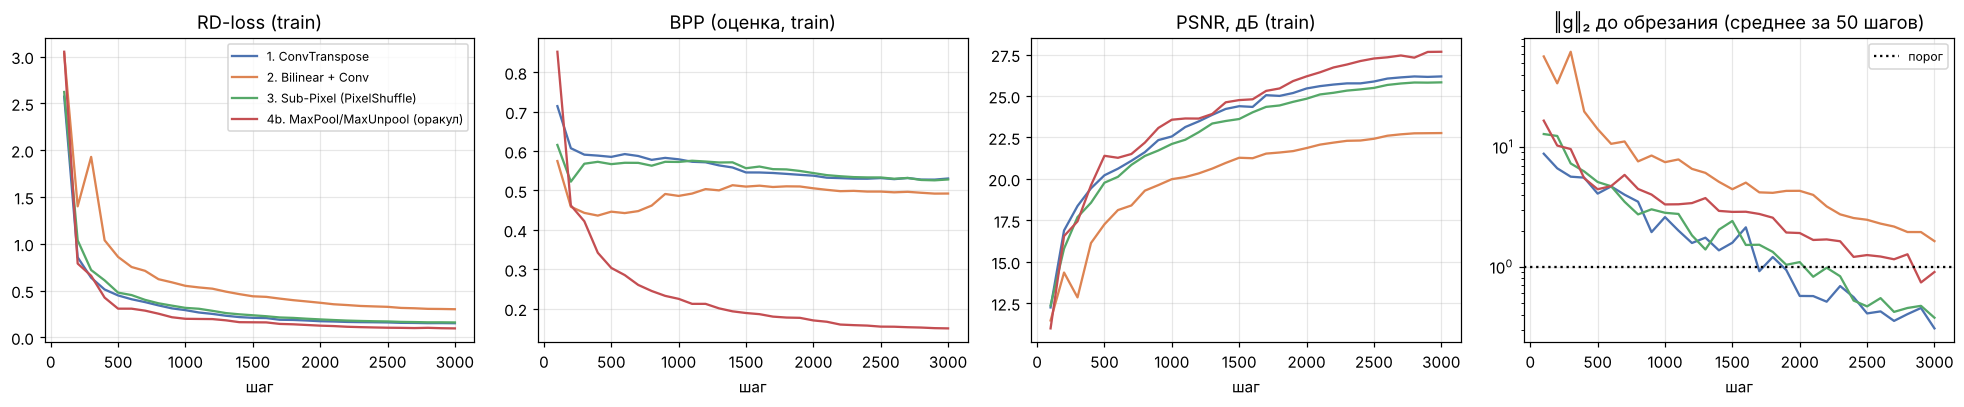

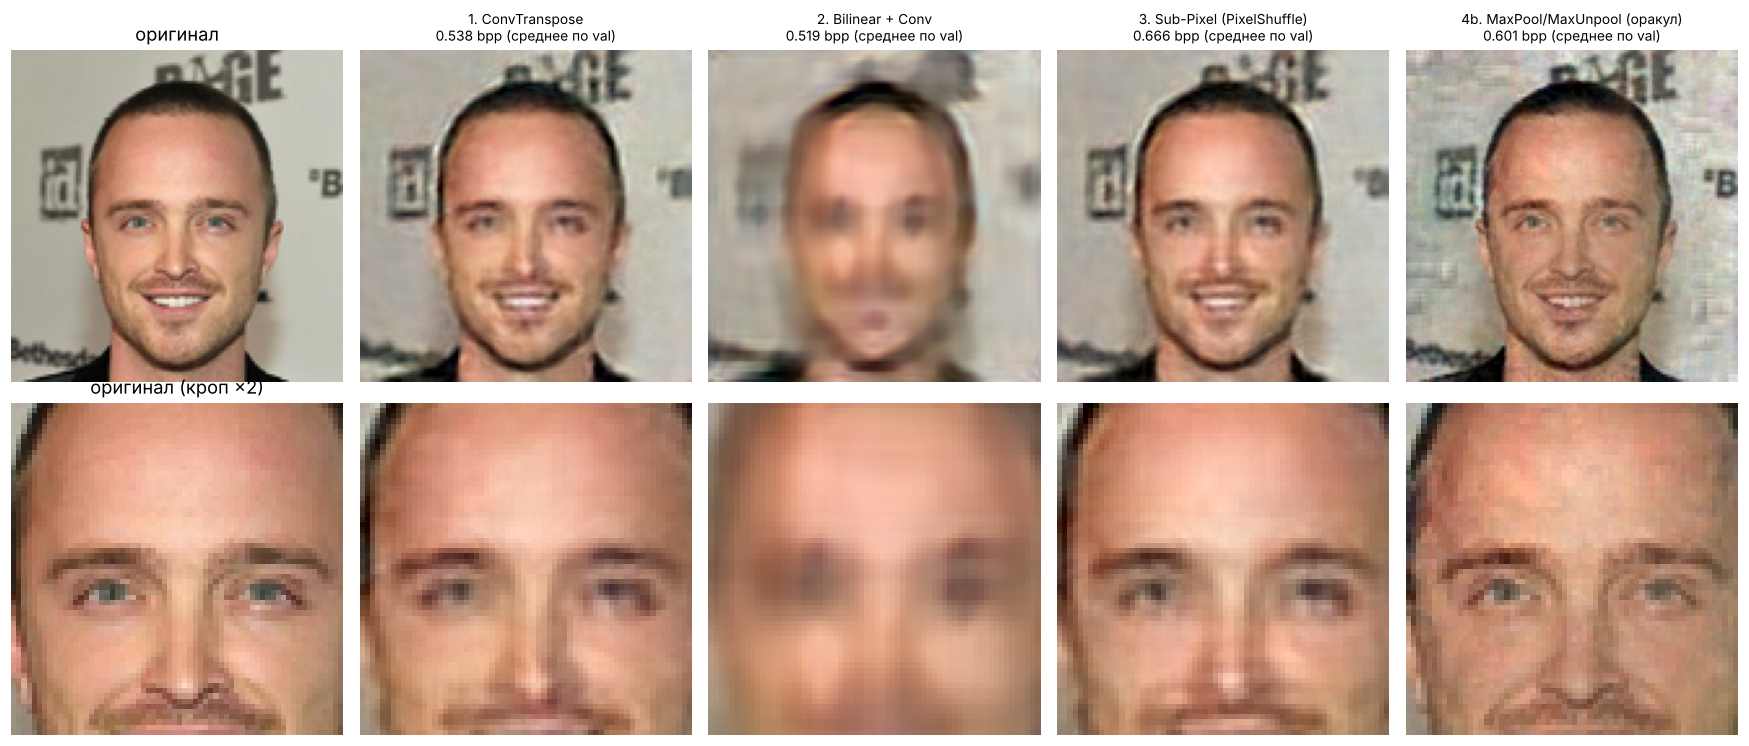

In [10]:
cols = {"transposed": "#4C72B0", "bilinear": "#DD8452", "subpixel": "#55A868", "maxunpool_oracle": "#C44E52"}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for key, log in LOGS.items():
    axes[0].plot(log.step, log.loss, color=cols[key], label=VARIANTS[key])
    axes[1].plot(log.step, log.bpp, color=cols[key])
    axes[2].plot(log.step, log.psnr, color=cols[key])
    axes[3].plot(log.step, log.gnorm, color=cols[key])
axes[0].set_title("RD-loss (train)"); axes[1].set_title("BPP (оценка, train)"); axes[2].set_title("PSNR, дБ (train)")
axes[3].set_title("‖g‖₂ до обрезания (среднее за 50 шагов)"); axes[3].axhline(CFG["CLIP_NORM"], color="k", ls=":", label="порог")
axes[3].set_yscale("log"); axes[3].legend(fontsize=8); axes[0].legend(fontsize=8)
for ax in axes: ax.set_xlabel("шаг")
plt.tight_layout(); plt.show()

# визуально: одно изображение, все варианты (смотрим на артефакты апсемплинга)
i0 = 3
fig, axes = plt.subplots(2, 5, figsize=(16, 6.8))
crop = (slice(30, 94), slice(30, 94))
axes[0, 0].imshow(X_val[i0].permute(1, 2, 0)); axes[0, 0].set_title("оригинал")
axes[1, 0].imshow(X_val[i0].permute(1, 2, 0)[crop]); axes[1, 0].set_title("оригинал (кроп ×2)")
for j, key in enumerate(VARIANTS, 1):
    r = var_df.loc[VARIANTS[key]]
    img = RECON[key][i0].permute(1, 2, 0)
    axes[0, j].imshow(img); axes[0, j].set_title(f"{VARIANTS[key]}\n{r.bpp:.3f} bpp (среднее по val)", fontsize=9)
    axes[1, j].imshow(img[crop])
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

### Выбор варианта для дальнейших экспериментов

Лучший вариант выбирается по **RD-loss на валидации** с реальным BPP: это та величина, которую оптимизирует обучение.
Оракул 4b в выборе не участвует, потому что без передачи индексов он не является кодеком.

In [11]:
valid_variants = ["transposed", "bilinear", "subpixel"]
BEST = min(valid_variants, key=lambda k: var_df.loc[VARIANTS[k], "rd_loss"])
print("Лучший вариант по RD-loss на валидации:", VARIANTS[BEST])
o = var_df.loc[VARIANTS["maxunpool_oracle"]]
print(f"Оракул MaxPool/MaxUnpool: {o.bpp:.3f} bpp за y,z + ≈{o['bpp_индексов']:.1f} bpp за индексы "
      f"= {o.bpp + o['bpp_индексов']:.1f} bpp (несжатое RGB-изображение — 24 bpp)")

Лучший вариант по RD-loss на валидации: 1. ConvTranspose
Оракул MaxPool/MaxUnpool: 0.601 bpp за y,z + ≈43.0 bpp за индексы = 43.6 bpp (несжатое RGB-изображение — 24 bpp)


## 7. Эксперимент 2: кривые «битрейт — качество» и сравнение с JPEG / WebP

Лучший вариант дообучается при λ_mid ещё `STEPS_MAIN_EXTRA` шагов, затем от этой точки перенастраивается на остальные λ
по `STEPS_FINETUNE` шагов. Чем больше λ, тем дороже биты и тем ниже битрейт. Перенастройка с общей стартовой точки
стандартна для экономии вычислений: rate-зависимыми в основном оказываются энтропийные модели и масштаб латента.

In [12]:
RD_MODELS, RD_LOGS = {}, {}
lam_mid = CFG["LAMBDA_MID"]
base = MODELS[BEST]
RD_LOGS[lam_mid] = pd.concat([LOGS[BEST], train(base, lam_mid, CFG["STEPS_MAIN_EXTRA"], f"{BEST} λ={lam_mid}").assign(
    step=lambda d: d.step + CFG["STEPS_COMPARE"])])
RD_MODELS[lam_mid] = base
torch.save(base.state_dict(), f"checkpoints/{BEST}_lam{lam_mid}.pt")
base_state = {k: v.clone() for k, v in base.state_dict().items()}
for lam in CFG["LAMBDAS"]:
    if lam == lam_mid:
        continue
    m = HyperpriorVAE(CFG["N"], CFG["M"], BEST)
    m.load_state_dict(base_state)
    RD_LOGS[lam] = train(m, lam, CFG["STEPS_FINETUNE"], f"{BEST} λ={lam}", seed=int(lam * 1000))
    RD_MODELS[lam] = m
    torch.save(m.state_dict(), f"checkpoints/{BEST}_lam{lam}.pt")

[transposed λ=0.1] step   500/3000 | loss 0.1787 | bpp 0.530 | PSNR 25.14 | MS-SSIM 0.9527 | LPIPS 0.0663 | ‖g‖ 1.63 (обрезано 75%) | val: bpp 0.490 PSNR 25.36 LPIPS 0.0858 | 1.6 мин


[transposed λ=0.1] step  1000/3000 | loss 0.1580 | bpp 0.535 | PSNR 25.86 | MS-SSIM 0.9612 | LPIPS 0.0538 | ‖g‖ 1.36 (обрезано 64%) | val: bpp 0.501 PSNR 26.14 LPIPS 0.0717 | 3.2 мин


[transposed λ=0.1] step  1500/3000 | loss 0.1413 | bpp 0.535 | PSNR 26.65 | MS-SSIM 0.9672 | LPIPS 0.0457 | ‖g‖ 0.78 (обрезано 23%) | val: bpp 0.524 PSNR 27.34 LPIPS 0.0585 | 4.8 мин


[transposed λ=0.1] step  2000/3000 | loss 0.1314 | bpp 0.538 | PSNR 27.11 | MS-SSIM 0.9717 | LPIPS 0.0403 | ‖g‖ 0.41 (обрезано 0%) | val: bpp 0.547 PSNR 27.86 LPIPS 0.0520 | 6.4 мин


[transposed λ=0.1] step  2500/3000 | loss 0.1269 | bpp 0.540 | PSNR 27.34 | MS-SSIM 0.9739 | LPIPS 0.0378 | ‖g‖ 0.32 (обрезано 0%) | val: bpp 0.583 PSNR 28.16 LPIPS 0.0480 | 8.1 мин


[transposed λ=0.1] step  3000/3000 | loss 0.1230 | bpp 0.539 | PSNR 27.54 | MS-SSIM 0.9755 | LPIPS 0.0357 | ‖g‖ 0.22 (обрезано 0%) | val: bpp 0.599 PSNR 28.28 LPIPS 0.0464 | 9.7 мин


... (5 outputs left out)

[transposed λ=0.25] step  1500/1500 | loss 0.1887 | bpp 0.400 | PSNR 26.75 | MS-SSIM 0.9656 | LPIPS 0.0464 | ‖g‖ 0.30 (обрезано 0%) | val: bpp 0.416 PSNR 27.39 LPIPS 0.0592 | 4.6 мин


[transposed λ=0.6] step   500/1500 | loss 0.3504 | bpp 0.317 | PSNR 24.30 | MS-SSIM 0.9344 | LPIPS 0.0785 | ‖g‖ 1.96 (обрезано 71%) | val: bpp 0.267 PSNR 25.12 LPIPS 0.1014 | 1.6 мин


[transposed λ=0.6] step  1000/1500 | loss 0.3202 | bpp 0.301 | PSNR 24.95 | MS-SSIM 0.9429 | LPIPS 0.0726 | ‖g‖ 0.90 (обрезано 28%) | val: bpp 0.261 PSNR 25.66 LPIPS 0.0923 | 3.1 мин


[transposed λ=0.6] step  1500/1500 | loss 0.3088 | bpp 0.299 | PSNR 25.22 | MS-SSIM 0.9477 | LPIPS 0.0660 | ‖g‖ 0.36 (обрезано 1%) | val: bpp 0.272 PSNR 25.96 LPIPS 0.0879 | 4.7 мин


In [13]:
rd_rows, RD_RECON, RD_RES = [], {}, {}
for lam in sorted(RD_MODELS):
    res, x_hat, n_clip = evaluate_model(RD_MODELS[lam], X_val)
    assert n_clip == 0
    RD_RECON[lam], RD_RES[lam] = x_hat, res
    rd_rows.append(summarize(res, codec=f"VAE ({VARIANTS[BEST]})", param=f"λ={lam}"))
rd_df = pd.DataFrame(rd_rows)
rd_df.style.format(precision=4)

,codec,param,bpp,bpp_est,psnr,msssim,msssim_db,lpips
0,VAE (1. ConvTranspose),λ=0.04,0.7600,0.7600,29.7981,0.9835,17.8152,0.0353
1,VAE (1. ConvTranspose),λ=0.1,0.5974,0.5969,28.7612,0.9768,16.3489,0.0499
2,VAE (1. ConvTranspose),λ=0.25,0.4158,0.4138,27.7967,0.9681,14.9634,0.0641
3,VAE (1. ConvTranspose),λ=0.6,0.2730,0.2705,26.3020,0.9515,13.1434,0.0939


### Классические кодеки на тех же 500 изображениях

* **JPEG** (libjpeg через Pillow, `optimize=True`, субдискретизация цветности 4:2:0 по умолчанию). Размер — весь файл.
  При 128×128 заголовок JPEG (таблицы квантования и Хаффмана, ~600 байт) сам по себе стоит около 0.3 bpp. Поэтому дополнительно
  показана кривая «JPEG, только данные скана» — нижняя оценка размера, как будто таблицы известны декодеру заранее.
* **WebP** (libwebp, lossy, `method=6`), размер — весь файл. Контейнер RIFF занимает около 30 байт.

In [14]:
def jpeg_scan_bytes(b):
    i = b.find(b"\xff\xda")                       # SOS
    L = int.from_bytes(b[i + 2:i + 4], "big")
    return len(b) - (i + 2 + L) - 2               # без заголовков и маркера EOI

def run_classic(fmt, qualities):
    rows, recon = [], {}
    imgs = (X_val.permute(0, 2, 3, 1).numpy() * 255).round().astype(np.uint8)
    for q in qualities:
        sizes, scan, dec = [], [], []
        for im in imgs:
            buf = io.BytesIO()
            if fmt == "JPEG":
                Image.fromarray(im).save(buf, format="JPEG", quality=q, optimize=True)
                scan.append(jpeg_scan_bytes(buf.getvalue()))
            else:
                Image.fromarray(im).save(buf, format="WEBP", quality=q, method=6)
            sizes.append(len(buf.getvalue()))
            dec.append(np.asarray(Image.open(io.BytesIO(buf.getvalue())).convert("RGB")))
        x_dec = torch.from_numpy(np.stack(dec)).permute(0, 3, 1, 2).float() / 255
        res = metrics_of(x_dec, X_val)
        res["bpp"] = np.array(sizes) * 8 / (128 * 128)
        recon[q] = (torch.from_numpy(np.stack(dec)).permute(0, 3, 1, 2).contiguous(), res["bpp"])   # uint8
        rows.append(summarize(res, codec=fmt, param=f"q={q}"))
        if fmt == "JPEG":
            res2 = dict(res); res2["bpp"] = np.array(scan) * 8 / (128 * 128)
            rows.append(summarize(res2, codec="JPEG (только скан)", param=f"q={q}"))
    return pd.DataFrame(rows), recon

t0 = time.time()
jpeg_df, JPEG_RECON = run_classic("JPEG", CFG["JPEG_Q"])
webp_df, WEBP_RECON = run_classic("WEBP", CFG["WEBP_Q"])
all_df = pd.concat([rd_df, jpeg_df, webp_df], ignore_index=True)
all_df.to_csv("artifacts/rd_results.csv", index=False)
print(f"JPEG/WebP: {time.time() - t0:.0f} c")
print("Минимальный размер файла JPEG при q=5: %.3f bpp, из них данные скана: %.3f bpp" %
      tuple(jpeg_df[jpeg_df.param == "q=5"].bpp.values[:2]) if "q=5" in set(jpeg_df.param) else "")

JPEG/WebP: 122 c
Минимальный размер файла JPEG при q=5: 0.336 bpp, из них данные скана: 0.189 bpp


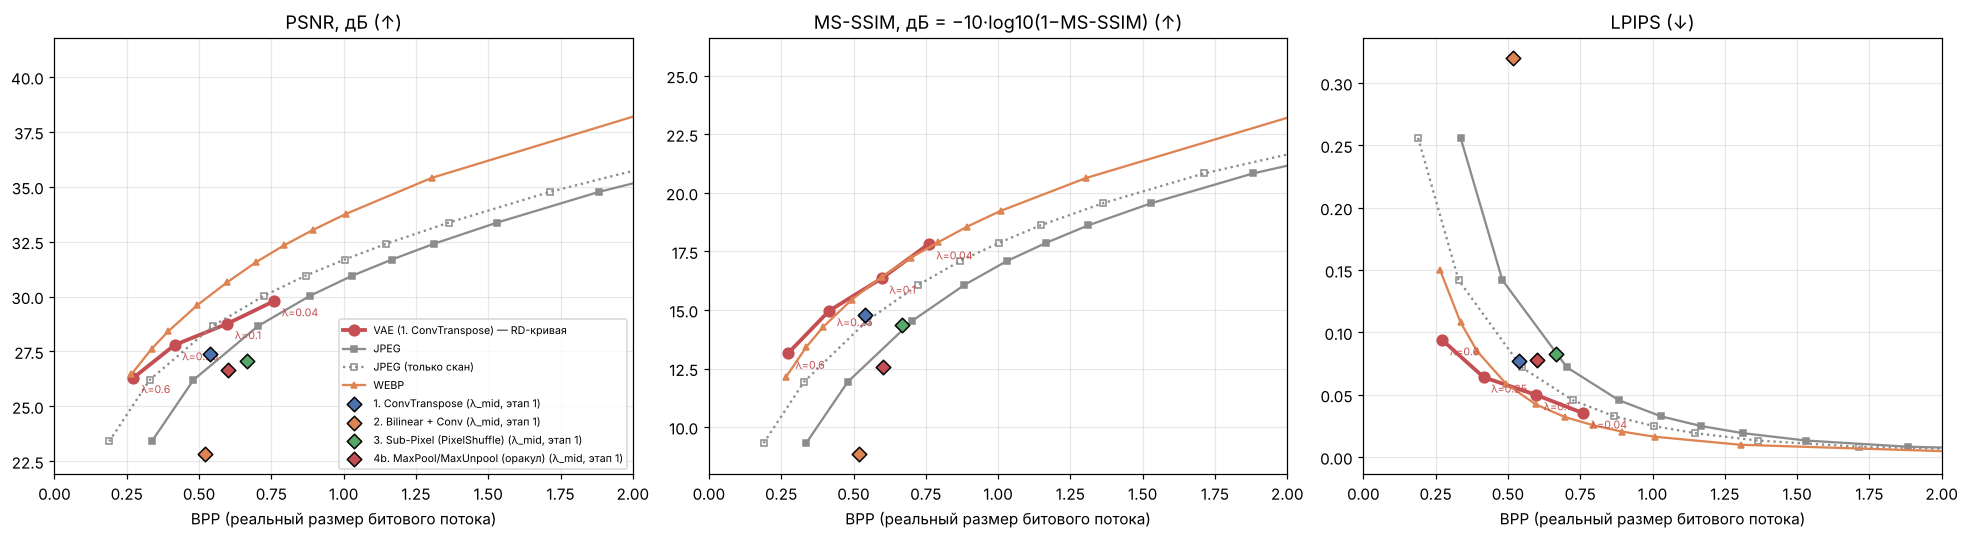

In [15]:
style = {"JPEG": dict(color="#8C8C8C", marker="s", ls="-"), "JPEG (только скан)": dict(color="#8C8C8C", marker="s", ls=":", mfc="none"),
         "WEBP": dict(color="#DD8452", marker="^", ls="-")}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (col, lab) in zip(axes, [("psnr", "PSNR, дБ (↑)"), ("msssim_db", "MS-SSIM, дБ = −10·log10(1−MS-SSIM) (↑)"), ("lpips", "LPIPS (↓)")]):
    for codec, d in all_df.groupby("codec", sort=False):
        d = d.sort_values("bpp")
        if codec.startswith("VAE"):
            ax.plot(d.bpp, d[col], color="#C44E52", marker="o", lw=2.5, ms=7, label=codec + " — RD-кривая")
            for _, r in d.iterrows():
                ax.annotate(r.param, (r.bpp, r[col]), textcoords="offset points", xytext=(5, -10), fontsize=7, color="#C44E52")
        else:
            ax.plot(d.bpp, d[col], label=codec, lw=1.5, ms=4, **style[codec])
    for key in VARIANTS:                     # варианты апсемплинга — отдельные точки при λ_mid
        r = var_df.loc[VARIANTS[key]]
        ax.scatter(r.bpp, r[col], color=cols[key], marker="D", s=45, edgecolor="k", zorder=5, label=f"{VARIANTS[key]} (λ_mid, этап 1)")
    ax.set_xlabel("BPP (реальный размер битового потока)"); ax.set_title(lab); ax.set_xlim(0, 2.0)
axes[0].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig("artifacts/rd_curves.png", dpi=130); plt.show()

### BD-rate (Bjøntegaard delta rate)

BD-rate — средняя разница битрейта при **одинаковом качестве** (Bjøntegaard, 2001). Кривые $\log(\text{rate})$ от качества
интерполируются кусочно-кубическими монотонными полиномами (PCHIP) и интегрируются по общему диапазону качества.
Отрицательное значение означает экономию бит относительно эталона. Считается только по перекрывающемуся диапазону качества.

In [16]:
from scipy.interpolate import PchipInterpolator

def bd_rate(r_ref, q_ref, r_test, q_test):
    lr_ref, lr_test = np.log(r_ref), np.log(r_test)
    o_ref, o_test = np.argsort(q_ref), np.argsort(q_test)
    lo, hi = max(min(q_ref), min(q_test)), min(max(q_ref), max(q_test))
    if hi <= lo:
        return np.nan, (lo, hi)
    f_ref = PchipInterpolator(np.asarray(q_ref)[o_ref], lr_ref[o_ref])
    f_test = PchipInterpolator(np.asarray(q_test)[o_test], lr_test[o_test])
    qq = np.linspace(lo, hi, 200)
    avg = np.trapezoid(f_test(qq) - f_ref(qq), qq) / (hi - lo)
    return (np.exp(avg) - 1) * 100, (lo, hi)

vae = all_df[all_df.codec.str.startswith("VAE")]
rows = []
for ref in ["JPEG", "JPEG (только скан)", "WEBP"]:
    d = all_df[all_df.codec == ref]
    for col, sign, name in [("psnr", 1, "PSNR"), ("msssim_db", 1, "MS-SSIM (дБ)"), ("lpips", -1, "LPIPS")]:
        bd, (lo, hi) = bd_rate(d.bpp.values, sign * d[col].values, vae.bpp.values, sign * vae[col].values)
        rows.append({"эталон": ref, "метрика": name, "BD-rate VAE, %": bd,
                     "диапазон качества": f"{sign * lo:.3f} … {sign * hi:.3f}" if sign > 0 else f"{-hi:.3f} … {-lo:.3f}"})
bd_df = pd.DataFrame(rows)
bd_df.style.format({"BD-rate VAE, %": "{:+.1f}"})

,эталон,метрика,"BD-rate VAE, %",диапазон качества
0,JPEG,PSNR,-28.0,26.302 … 29.798
1,JPEG,MS-SSIM (дБ),-41.8,13.143 … 17.815
2,JPEG,LPIPS,-42.5,0.035 … 0.094
3,JPEG (только скан),PSNR,-4.5,26.302 … 29.798
4,JPEG (только скан),MS-SSIM (дБ),-27.2,13.143 … 17.815
5,JPEG (только скан),LPIPS,-27.2,0.035 … 0.094
6,WEBP,PSNR,+27.1,26.451 … 29.798
7,WEBP,MS-SSIM (дБ),-5.4,13.143 … 17.815
8,WEBP,LPIPS,-8.5,0.035 … 0.094


### Визуальное сравнение при близком битрейте

Для двух валидационных изображений показаны реконструкции VAE при самом низком и среднем битрейте, а рядом — JPEG и WebP
с качеством, при котором размер файла **этого изображения** ближе всего к размеру потока VAE.

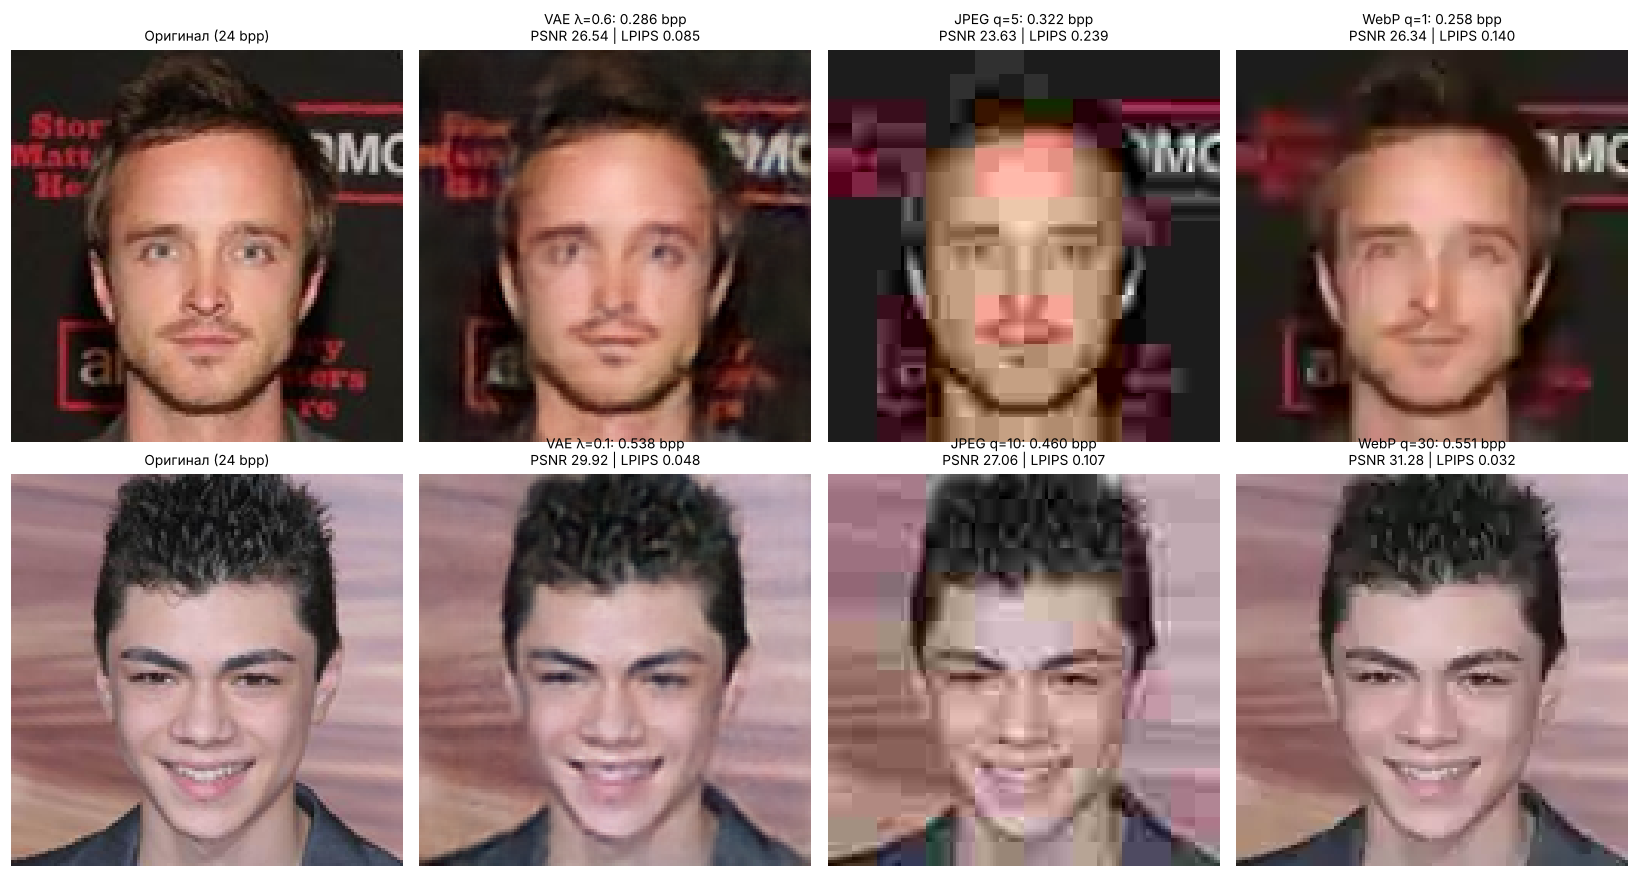

In [17]:
def closest(recon_dict, i, target_bpp):
    q = min(recon_dict, key=lambda q: abs(recon_dict[q][1][i] - target_bpp))
    x, b = recon_dict[q]
    return x[i].float() / 255, b[i], q

lams = sorted(RD_MODELS)
show = [(lams[-1], 11), (lams[1], 42)]      # (λ, индекс изображения): низкий и средний битрейт
fig, axes = plt.subplots(len(show), 4, figsize=(15, 4 * len(show)))
for row, (lam, i) in enumerate(show):
    i = min(i, len(X_val) - 1)
    res = RD_RES[lam]
    b = res["bpp"][i]
    panels = [("Оригинал (24 bpp)", X_val[i]),
              (f"VAE λ={lam}: {b:.3f} bpp\nPSNR {res['psnr'][i]:.2f} | LPIPS {res['lpips'][i]:.3f}", RD_RECON[lam][i].float() / 255)]
    for nm, rec in [("JPEG", JPEG_RECON), ("WebP", WEBP_RECON)]:
        x, bb, q = closest(rec, i, b)
        p = psnr_fn(x[None], X_val[i:i + 1]).item(); l = lpips_fn(x[None], X_val[i:i + 1]).item()
        panels.append((f"{nm} q={q}: {bb:.3f} bpp\nPSNR {p:.2f} | LPIPS {l:.3f}", x))
    for ax, (t, im) in zip(axes[row], panels):
        ax.imshow(im.permute(1, 2, 0).clamp(0, 1)); ax.set_title(t, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig("artifacts/visual_comparison.png", dpi=120); plt.show()

### Куда уходят биты: карта распределения rate

Для каждой позиции латента 8×8 суммируется $-\log_2 p(\hat y_i\mid\hat z)$ по 128 каналам, то есть число бит,
которые кодек тратит на соответствующий участок 16×16 пикселей. Также показаны предсказанный гиперприором масштаб σ
и «нормированный» латент $(\hat y-\mu)/\sigma$. Если гиперприор хорошо моделирует $\hat y$, нормированный латент близок
к белому шуму.

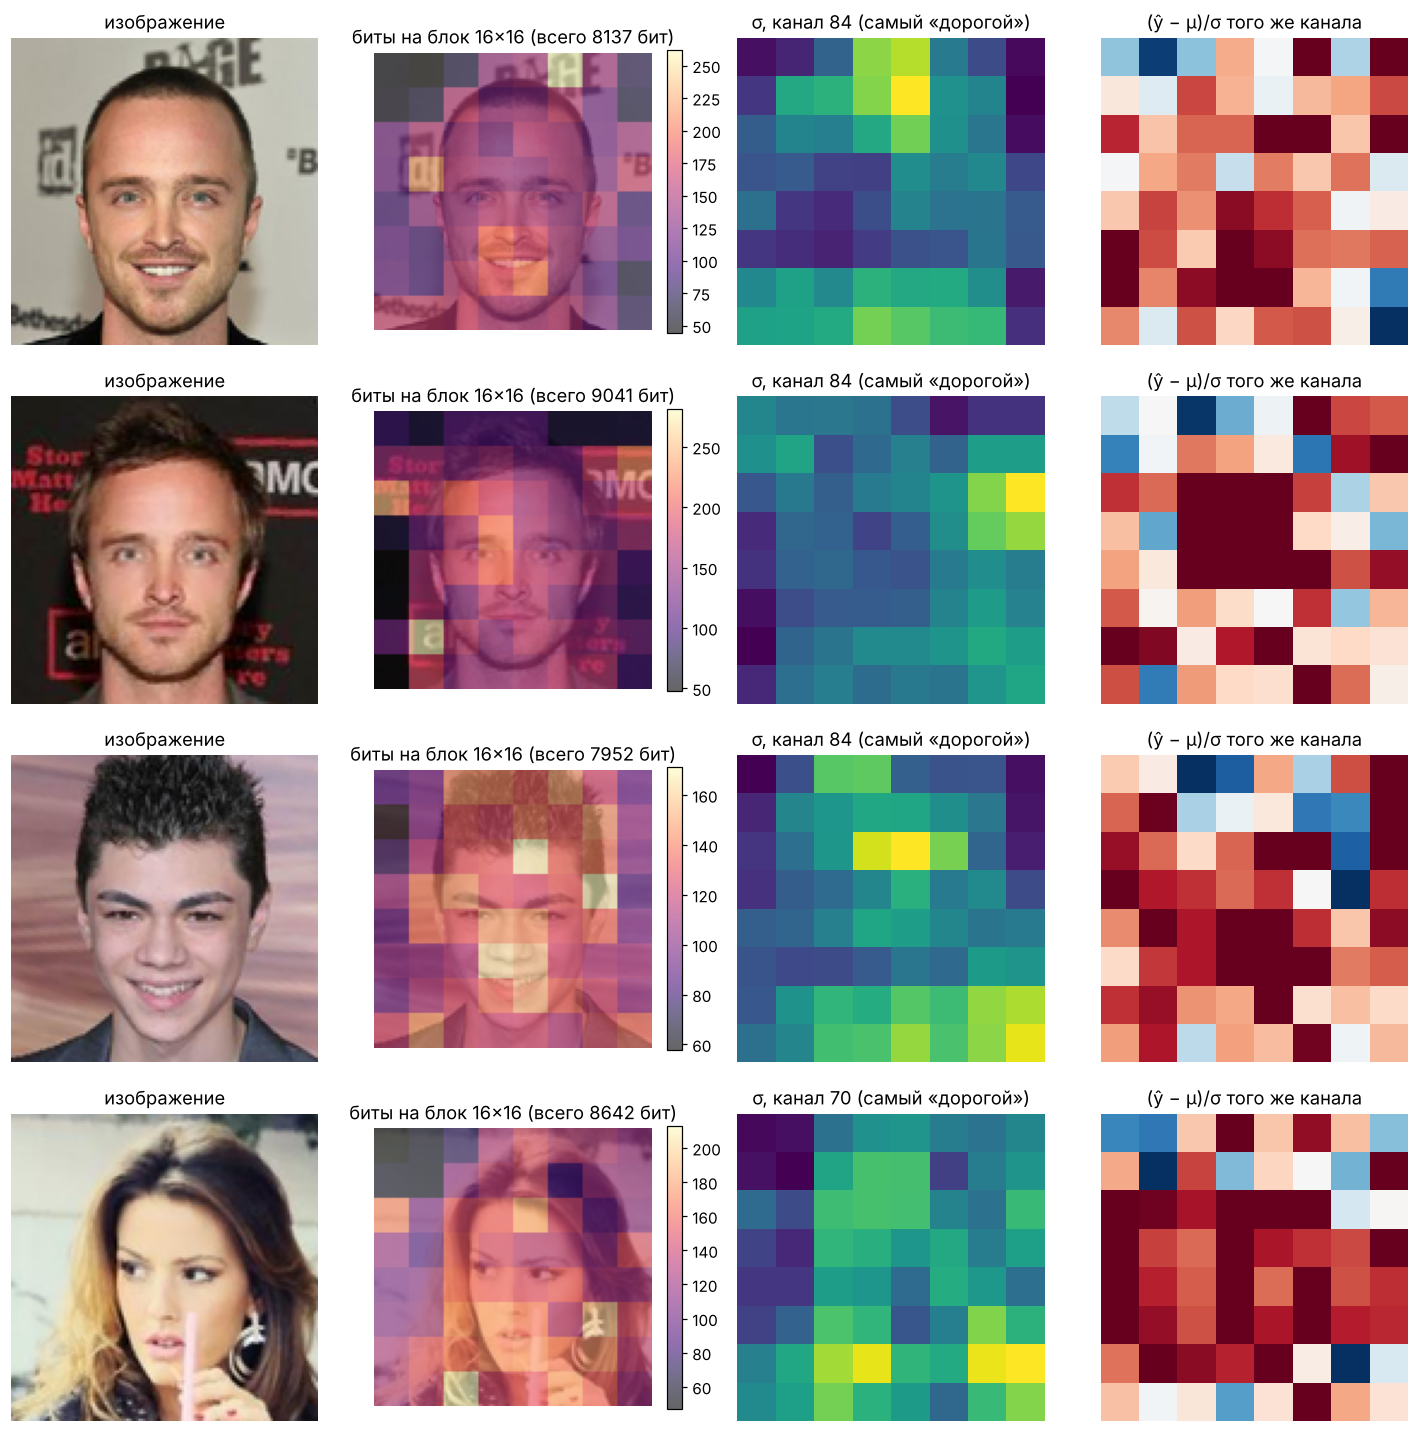

λ=0.04: активных каналов y: 128/128, доля бит гиперприора z: 10.6%


λ=0.1: активных каналов y: 128/128, доля бит гиперприора z: 12.7%


λ=0.25: активных каналов y: 128/128, доля бит гиперприора z: 13.9%


λ=0.6: активных каналов y: 128/128, доля бит гиперприора z: 14.8%


In [18]:
lam = CFG["LAMBDA_MID"]; model = RD_MODELS[lam]
idxs = [3, 11, 42, 77]
fig, axes = plt.subplots(len(idxs), 4, figsize=(13, 3.3 * len(idxs)))
with torch.no_grad():
    for r, i in enumerate(idxs):
        i = min(i, len(X_val) - 1)
        out = model(X_val[i:i + 1])
        bits_map = (-torch.log2(out["lik_y"][0])).sum(0)
        ch = out["lik_y"][0].log2().neg().flatten(1).sum(1).argmax()
        axes[r, 0].imshow(X_val[i].permute(1, 2, 0)); axes[r, 0].set_title("изображение")
        axes[r, 1].imshow(X_val[i].permute(1, 2, 0)); im = axes[r, 1].imshow(
            F.interpolate(bits_map[None, None], size=128, mode="nearest")[0, 0], cmap="magma", alpha=0.6)
        axes[r, 1].set_title(f"биты на блок 16×16 (всего {bits_map.sum():.0f} бит)"); plt.colorbar(im, ax=axes[r, 1], fraction=0.046)
        axes[r, 2].imshow(out["sigma"][0, ch], cmap="viridis"); axes[r, 2].set_title(f"σ, канал {ch.item()} (самый «дорогой»)")
        axes[r, 3].imshow(((torch.round(out["y"]) - out["mu"]) / out["sigma"].clamp_min(SCALE_MIN))[0, ch], cmap="RdBu", vmin=-3, vmax=3)
        axes[r, 3].set_title("(ŷ − μ)/σ того же канала")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

# доля «включённых» каналов латента: каналы, на которые в среднем тратится < 0.01 бита, фактически отключены
with torch.no_grad():
    for lam in sorted(RD_MODELS):
        o = RD_MODELS[lam](X_val[:100])
        per_ch = (-torch.log2(o["lik_y"])).sum((0, 2, 3)) / 100
        print(f"λ={lam}: активных каналов y: {(per_ch > 0.01).sum().item()}/{per_ch.numel()}, "
              f"доля бит гиперприора z: {(-torch.log2(o['lik_z'])).sum().item() / ((-torch.log2(o['lik_y'])).sum().item() + (-torch.log2(o['lik_z'])).sum().item()):.1%}")

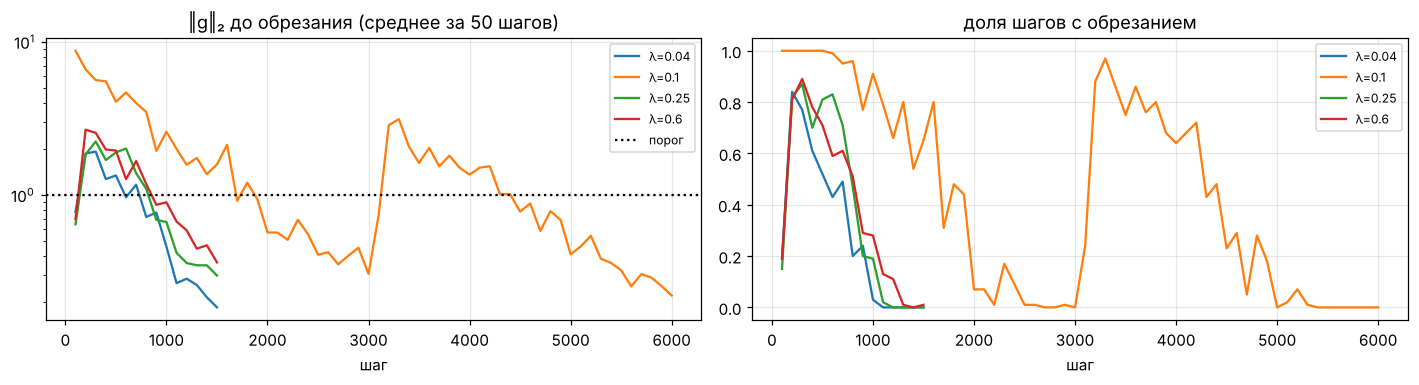

In [19]:
# Градиентное обрезание: насколько часто срабатывало и какие были нормы
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for lam, log in sorted(RD_LOGS.items()):
    axes[0].plot(log.step, log.gnorm, label=f"λ={lam}")
    axes[1].plot(log.step, log.clipped, label=f"λ={lam}")
axes[0].axhline(CFG["CLIP_NORM"], color="k", ls=":", label="порог"); axes[0].set_yscale("log")
axes[0].set_title("‖g‖₂ до обрезания (среднее за 50 шагов)"); axes[1].set_title("доля шагов с обрезанием")
for ax in axes: ax.set_xlabel("шаг"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Итоговая таблица и выводы

In [20]:
summary = pd.concat([var_df.reset_index().rename(columns={"variant": "модель"}).assign(этап="1: апсемплинг, λ_mid"),
                     rd_df.rename(columns={"codec": "модель"}).assign(этап="2: RD-кривая")], ignore_index=True)
cols_show = ["этап", "модель", "param", "bpp", "bpp_est", "psnr", "msssim", "msssim_db", "lpips"]
summary = summary.reindex(columns=cols_show)
summary.to_csv("artifacts/summary.csv", index=False)
display(summary.style.format(precision=4))
print("Разница реального и оценённого BPP (накладные расходы ANS + заголовок), среднее:",
      f"{(rd_df.bpp - rd_df.bpp_est).mean():+.4f} bpp")

,этап,модель,param,bpp,bpp_est,psnr,msssim,msssim_db,lpips
0,"1: апсемплинг, λ_mid",1. ConvTranspose,nan,0.5383,0.5356,27.3998,0.9667,14.7761,0.0772
1,"1: апсемплинг, λ_mid",2. Bilinear + Conv,nan,0.5189,0.5165,22.8101,0.8692,8.8336,0.3203
2,"1: апсемплинг, λ_mid",3. Sub-Pixel (PixelShuffle),nan,0.6665,0.6710,27.0738,0.9635,14.3761,0.0828
3,"1: апсемплинг, λ_mid",4b. MaxPool/MaxUnpool (оракул),nan,0.6010,0.6062,26.6342,0.9447,12.5762,0.0777
4,2: RD-кривая,VAE (1. ConvTranspose),λ=0.04,0.7600,0.7600,29.7981,0.9835,17.8152,0.0353
5,2: RD-кривая,VAE (1. ConvTranspose),λ=0.1,0.5974,0.5969,28.7612,0.9768,16.3489,0.0499
6,2: RD-кривая,VAE (1. ConvTranspose),λ=0.25,0.4158,0.4138,27.7967,0.9681,14.9634,0.0641
7,2: RD-кривая,VAE (1. ConvTranspose),λ=0.6,0.2730,0.2705,26.3020,0.9515,13.1434,0.0939


Разница реального и оценённого BPP (накладные расходы ANS + заголовок), среднее: +0.0013 bpp


### Выводы

1. **Кодек работает.** Все латенты сжаты ANS в реальный битовый поток и распакованы без единой ошибки в символах.
   Реальный BPP отличается от оценки по правдоподобию в среднем на **+0.001 bpp**: накладные расходы ANS и заголовка ничтожны.
   Значит, обучаемая оценка rate (KL-член VAE) точно предсказывает размер файла.
2. **RD-кривая** (λ = 0.04 … 0.6): от **0.27 bpp** (PSNR 26.3 дБ, MS-SSIM 0.952, LPIPS 0.094)
   до **0.76 bpp** (PSNR 29.8 дБ, MS-SSIM 0.984, LPIPS 0.035).
3. **Сравнение с классическими кодеками** (BD-rate, отрицательное значение — экономия бит):
   * против **JPEG**: −28% по PSNR, −42% по MS-SSIM, −43% по LPIPS. Даже против «JPEG без заголовков»: −5%, −27% и −27%;
   * против **WebP**: по MS-SSIM (−5%) и LPIPS (−9%) VAE лучше, по PSNR хуже (+27% бит). Модель оптимизирует
     перцептивную смесь MSE + MS-SSIM + LPIPS и учится всего ~6 тыс. шагов на CPU, тогда как WebP — зрелый кодек
     с внутрикадровым предсказанием. Визуально при ~0.3 bpp JPEG распадается на блоки, WebP размывает детали,
     а VAE сохраняет структуру лица и волос.
4. **Способы увеличения размера тензора** при равном бюджете (3 000 шагов, λ = 0.1):
   * **транспонированная свёртка** — лучший RD-компромисс (27.4 дБ / LPIPS 0.077 при 0.54 bpp) и самый дешёвый декодер
     (0.16 GMAC), поэтому она выбрана для RD-кривой;
   * **Sub-Pixel** почти не уступает по качеству (27.1 дБ / 0.083), но тратит больше бит (0.67 bpp) и в 1.4 раза больше вычислений;
   * **билинейная интерполяция + свёртка** обучается заметно хуже (22.8 дБ / LPIPS 0.32). В начале обучения у неё были
     самые большие нормы градиента: в среднем по 100 шагам до 62 против 9–17 у остальных вариантов, и обрезание
     срабатывало почти на каждом шаге (99.7%). Декодер работает на выходном разрешении,
     поэтому он в 4 раза дороже. При таком бюджете шагов вариант явно недообучен;
   * **Max Unpooling** с фиксированными индексами математически эквивалентен транспонированной свёртке, что проверено численно.
     С «настоящими» индексами (оракул 4b) качество при 0.60 bpp сопоставимо, но передача индексов стоит **≈ 43 bpp**,
     больше несжатого изображения (24 bpp). Поэтому в задаче сжатия MaxUnpool с индексами энкодера неприменим.
5. **Градиентное обрезание** по глобальной норме было необходимо. Без нижней границы правдоподобий и обрезания обучение
   при lr = 10⁻³ давало NaN, а у билинейного декодера — взрыв градиентов. Обрезание активно почти всё начало обучения
   и затихает к концу этапов (‖g‖ < 1).
6. **Распределение бит** осмысленно: больше всего бит уходит на рот и зубы, глаза, контуры волос и текст на фоне,
   меньше всего — на однородный фон. Гиперприор занимает 11–15% потока, и его доля растёт с уменьшением битрейта.
   При этом нормированный латент (ŷ − μ)/σ далёк от белого шума и систематически смещён: гиперприор недообучен.
   Это прямой резерв экономии бит при более долгом обучении.
7. **Что улучшить:** обучать дольше на GPU (статьи — 10⁵–10⁶ шагов), увеличить N/M, добавить авторегрессионный или
   канально-авторегрессионный контекст в энтропийную модель (Minnen et al., 2018/2020). Это обычно даёт ещё 10–20% экономии бит.